---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

Notebook Logistic Regression: **L1 dan One-Hot Dewasa serta Anak** (tahap 3 dari 4)

---

## Group 17 (DerbyCounty)

- Juan Oloando Simanungkalit (13524032) - juanoloando.s@gmail.com
- Nashiruddin Akram (13524090) - akrambaasir@gmail.com
- Reinsen Silitonga (13524093) - reinsilitonga12@gmail.com
- Arghawisesa Dwinanda Arham (13524100) - arghaku.argha@gmail.com
- Manuel Thimoty Silalahi (13524102) - manuelsilalahi06@gmail.com

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)
12. [**Bonus**](#12)
13. [**Referensi**](#13)

---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Penyelenggara penginapan ingin memprediksi apakah sebuah pemesanan akan dibatalkan (`is_canceled`) dari data pemesanan seperti lead time, jumlah malam, harga, kanal pemesanan, dan permintaan khusus. Notebook ini mengerjakan model **Logistic Regression** dengan fokus pada regularisasi L1 dan one-hot fitur diskrit (jumlah dewasa dan anak).

## Aim

Membangun Logistic Regression from scratch dengan regularisasi L1, L2, dan Elastic Net, lalu menaikkan Macro F1 lewat preprocessing khusus model linear dan tuning hyperparameter, dengan pipeline yang reproducible.

Notebook ini adalah tahap 3 dari 4 tahap tuning (`lr_fe`, `lr_target_bins`, `lr_l1_onehot`, `lr_cross_bins`). Prediksi test yang dihasilkan sama persis dengan file `submission_lr_tuning_l1_onehot.csv` yang sudah diunggah ke Kaggle dengan public score **0,83480**.

## Metric

Macro F1 = rata-rata F1 kelas 0 dan F1 kelas 1. Kedua kelas berbobot sama, jadi model tidak cukup hanya bagus di kelas mayoritas. Metrik tambahan untuk analisis adalah log-loss, confusion matrix, presisi, dan recall.

## Dataset

`train.csv` berisi 27.373 baris dengan 17 fitur dan label, `test.csv` berisi 6.844 baris tanpa label. Ada missing value, duplikat, dan nilai tidak valid.

## Approach

Sama dengan `lr_target_bins`, ditambah one-hot `num_adults` dan `num_children`, dan regularisasi diganti L1 (`C = 0,1`). Dari 2.097 kolom hanya 1.119 yang dipakai karena L1 membuat sisanya bernilai nol. Model: L1, solver FISTA, threshold 0,45.

Semua statistik preprocessing hanya dipelajari dari data latih. Skor dihitung dari prediksi out-of-fold (OOF) stratified 5-fold, dan threshold dipilih dari OOF yang memberi Macro F1 tertinggi. Hasil OOF notebook ini adalah **0,8297** (std antar fold 0,0031).

Bagian lain yang mengikuti template (KNN, Decision Tree, SVM, dan Naive Bayes) dikerjakan anggota lain, jadi dikosongkan di notebook ini.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

Notebook ini bisa dijalankan di dua tempat tanpa mengubah kode:

| | Google Colab | Laptop (VS Code, dari dalam folder repo) |
| --- | --- | --- |
| Perangkat training | GPU jika runtime memakai T4, selain itu CPU | CPU (NumPy) |
| Kode `src` | di-clone dari GitHub atau dari folder `/content/IF3170_G17_DerbyCounty` | dibaca dari folder repo |
| Pemasangan paket | CuPy dan `imageio-ffmpeg` dipasang otomatis jika belum ada | tidak ada yang dipasang otomatis |
| Bagian berat (grid `C`, saga, gradient descent) | menyala jika memakai GPU | mati |

Variabel `USE_GPU` bernilai `True` hanya di Colab. Ubah ke `True` secara manual untuk memakai GPU lokal (CuPy harus sudah terpasang). Kalau repo masih private, simpan token GitHub dengan akses baca di Colab Secrets dengan nama `GITHUB_TOKEN`.

In [1]:
import importlib
import importlib.util
import os
import re
import subprocess
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules

# GPU dipakai otomatis di Colab dan di laptop default-nya CPU, ubah ke True untuk memakai GPU lokal
USE_GPU = IN_COLAB

# Alamat repo yang di-clone di Colab dan ganti REPO_BRANCH jika kode terbaru belum di-merge ke main
REPO_URL    = 'https://github.com/re1nsilitonga/IF3170_G17_DerbyCounty.git'
REPO_BRANCH = 'main'
REPO_DIR    = Path('/content/IF3170_G17_DerbyCounty')


# Jalankan perintah tanpa shell dan kembalikan hasilnya sebagai teks
def run(cmd, **kwargs):
    return subprocess.run(cmd, capture_output=True, text=True, **kwargs)


# Cek GPU lewat nvidia-smi dan hanya jika GPU memang mau dipakai
HAS_GPU = False
smi = None
if USE_GPU:
    try:
        smi = run(['nvidia-smi'])
        HAS_GPU = smi.returncode == 0
    except FileNotFoundError:
        HAS_GPU = False
    if HAS_GPU:
        print('GPU      :', run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader']).stdout.strip())
    else:
        print('GPU      : tidak ada, training berjalan di CPU (pilih Runtime > Change runtime type > T4 GPU)')
else:
    print('GPU      : tidak dipakai (USE_GPU = False), training berjalan di CPU')

# Pasang CuPy sesuai versi CUDA runtime jika belum ada, hanya otomatis di Colab
if HAS_GPU and importlib.util.find_spec('cupy') is None:
    if IN_COLAB:
        found = re.search(r'CUDA Version:\s*(\d+)', smi.stdout)
        package = 'cupy-cuda13x' if found and int(found.group(1)) >= 13 else 'cupy-cuda12x'
        print('memasang', package)
        result = run([sys.executable, '-m', 'pip', 'install', '-q', f'{package}[ctk]'])
        if result.returncode != 0:
            print(result.stderr[-800:])
        importlib.invalidate_caches()
    else:
        print('CuPy belum terpasang di environment lokal, pasang manual untuk memakai GPU lokal')

if HAS_GPU:
    try:
        import cupy
        HAS_GPU = cupy.cuda.runtime.getDeviceCount() > 0
        print('CuPy     :', cupy.__version__)
    except Exception as e:
        HAS_GPU = False
        print('CuPy tidak bisa dipakai, training berjalan di CPU:', type(e).__name__)

# Pustaka penulis video untuk bagian bonus kontur, dipasang otomatis hanya di Colab
if IN_COLAB and importlib.util.find_spec('imageio_ffmpeg') is None:
    run([sys.executable, '-m', 'pip', 'install', '-q', 'imageio-ffmpeg'])


# Cari root repo yaitu folder yang berisi src/models dari folder kerja
def find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'src' / 'models').is_dir():
            return p
    return None


# Ambil token GitHub dari environment atau Colab Secrets, hanya perlu jika repo masih private
def github_token():
    token = os.environ.get('GITHUB_TOKEN', '')
    if not token and IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get('GITHUB_TOKEN') or ''
        except Exception:
            token = ''
    return token


ROOT = find_root()
if ROOT is None:
    if not IN_COLAB:
        raise RuntimeError('folder repo tidak ditemukan, jalankan notebook dari dalam folder repo '
                           '(yang berisi src/models) atau buka notebook ini dari folder src/experiments/lr')
    if REPO_DIR.exists():
        run(['git', '-C', str(REPO_DIR), 'pull', '--ff-only'])
    else:
        token = github_token()
        url = REPO_URL.replace('https://', f'https://{token}@') if token else REPO_URL
        env = {**os.environ, 'GIT_TERMINAL_PROMPT': '0'}
        result = run(['git', 'clone', '--depth', '1', '--branch', REPO_BRANCH, url, str(REPO_DIR)], env=env)
        if result.returncode != 0:
            message = result.stderr.replace(token, '***') if token else result.stderr
            raise RuntimeError('git clone gagal. Jika repo masih private, simpan token GitHub di Colab Secrets '
                               'dengan nama GITHUB_TOKEN. Alternatifnya unggah folder repo ke /content.\n' + message)
    ROOT = REPO_DIR

sys.path.insert(0, str(ROOT / 'src'))
print('Repo     :', ROOT, f"(commit {run(['git', '-C', str(ROOT), 'rev-parse', '--short', 'HEAD']).stdout.strip()})")

GPU      : tidak dipakai (USE_GPU = False), training berjalan di CPU
Repo     : C:\ITB\IF\5\AI\TUBES\IF3170_G17_DerbyCounty (commit d231463)


## Import Libraries

Every import of the notebook is kept in this cell. Model dan preprocessing from scratch ada di `src/models/logistic_regression.py` dan `src/preprocessing/lr.py`. scikit-learn hanya dipakai untuk membagi data, menghitung log-loss, dan membandingkan hasil di bagian Comparison with scikit-learn.

In [2]:
import hashlib
import random
import shutil
import tempfile
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Image, Markdown, Video, display
from matplotlib.animation import FFMpegWriter, FuncAnimation, PillowWriter
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.metrics import log_loss
from sklearn.model_selection import train_test_split

from models import LogisticRegression
from preprocessing import LRPreprocessor, add_features, clean_train, mark_invalid
from preprocessing.lr import target_edges
from utils import (best_threshold, confusion_matrix, cross_val_proba, f1_per_class, fold_scores,
                   load_model, macro_f1, save_model, stratified_kfold)

print('numpy', np.__version__, '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__)

numpy 2.5.5 | pandas 3.1.1 | scikit-learn 1.9.1


## Settings

Paths and shared constants are kept in this class.

In [3]:
class Settings:
    SEED       = 5
    CV_SEED    = 42
    ID_COLUMN  = 'id'
    TARGET     = 'is_canceled'
    TEST_SIZE  = 0.2
    N_FOLDS    = 5

    DATA_DIR   = ROOT / 'data'
    OUTPUT_DIR = ROOT / 'output'
    FIG_DIR    = OUTPUT_DIR / 'figures'

    # preprocessing
    SR          = {'special_requests': 3, 'arrival_month': 12, 'num_adults': 3, 'num_children': 3}
    BINS        = ['days_before_arrival', 'nightly_rate_idr', 'rate_per_guest', 'arrival_index',
                   'arrival_dayofyear', 'total_nights', 'weekday_nights']
    INTER       = ['days_before_arrival', 'nightly_rate_idr', 'arrival_index', 'special_requests',
                   'arrival_month_sin', 'arrival_month_cos', 'total_nights', 'rate_per_guest',
                   'arrival_dayofyear_sin', 'arrival_dayofyear_cos', 'num_adults', 'num_children',
                   'weekend_nights', 'weekday_nights']
    BIN_PARAMS  = dict(bin_method='target', n_bins=16, bin_min_leaf=300)
    PREP_PARAMS = dict(onehot_cols=SR, bin_cols=BINS, interaction_cols=INTER, **BIN_PARAMS)

    # Logistic Regression
    LR_PARAMS   = dict(penalty='l1', C=0.1, solver='fista', tol=1e-4)
    THRESHOLD   = 0.45
    # float64 memberi hasil yang sama dengan CPU sampai ketelitian numerik
    DEVICE      = 'gpu' if HAS_GPU else 'cpu'
    DTYPE       = 'float64'
    EXPECTED_OOF = 0.8297

    # tuning dan perbandingan, saklar bagian berat menyala di GPU dan mati di CPU, ubah manual untuk memaksa
    C_GRID            = [0.03, 0.1, 0.3]
    RUN_C_SWEEP       = DEVICE == 'gpu'
    RUN_CPU_CHECK     = DEVICE == 'gpu'
    RUN_SK_L1         = DEVICE == 'gpu'
    RUN_OPTIMIZER_GD  = DEVICE == 'gpu'

    # bonus
    COST_FP, COST_FN  = 2, 1
    CONTOUR_FEATURE   = 'special_requests'
    VIDEO_NAME        = 'lr_l1_onehot_contour'
    VIDEO_FPS         = 12

    EXP_NAME     = 'lr_l1_onehot'
    MODEL_PATH   = OUTPUT_DIR / 'models' / f'{EXP_NAME}.pkl'
    SUB_PATH     = OUTPUT_DIR / 'submissions' / f'submission_{EXP_NAME}.csv'
    # file submission lama yang sudah diunggah ke Kaggle, dipakai untuk memeriksa hasil notebook ini
    REF_SUB_PATH = OUTPUT_DIR / 'submissions' / 'submission_lr_tuning_l1_onehot.csv'

CFG = Settings()
for folder in (CFG.OUTPUT_DIR / 'models', CFG.OUTPUT_DIR / 'submissions', CFG.FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print('device', CFG.DEVICE, '| dtype', CFG.DTYPE)

device cpu | dtype float64


Penjelasan isi `Settings`:

| Nama | Nilai | Arti |
|---|---|---|
| `SEED` | 5 | seed split holdout 80:20, sama dengan notebook model lain |
| `CV_SEED`, `N_FOLDS` | 42, 5 | seed dan jumlah fold untuk OOF, dipakai memilih threshold |
| `SR` | dict | fitur diskrit yang di-one-hot, nilai di atas batas digabung ke batas atas |
| `BINS` | 7 fitur | fitur numerik yang ditambah versi bin |
| `INTER` | 14 fitur | kolom yang dikalikan dengan seluruh kolom lain (interaksi) |
| `BIN_PARAMS` | dict | cara binning: berbasis target, 16 bin dengan minimal 300 baris |
| `LR_PARAMS` | L1, `C = 0,1` | jenis regularisasi, kekuatan regularisasi (kebalikan), solver FISTA, dan toleransi berhenti |
| `THRESHOLD` | 0,45 | batas probabilitas batal yang memaksimalkan Macro F1 pada OOF |
| `DEVICE`, `DTYPE` | cpu atau gpu, float64 | perangkat training dan presisi |
| `RUN_*` | True atau False | saklar bagian yang lambat |

## Seed Everything

A fixed seed keeps the results reproducible.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [5]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={CFG.ID_COLUMN: str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={CFG.ID_COLUMN: str})
sample   = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={CFG.ID_COLUMN: str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}  Sample submission: {sample.shape}')

Train: (27373, 19)  Test: (6844, 18)  Sample submission: (6844, 2)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [6]:
def types(df):
    kinds = ['numeric' if pd.api.types.is_numeric_dtype(df[column]) else 'categorical' for column in df]
    return pd.DataFrame({'dtype': df.dtypes.astype(str), 'kind': kinds, 'unique': df.nunique()})

In [7]:
types(train_df)

,dtype,kind,unique
id,str,categorical,27373
num_adults,float64,numeric,5
num_children,float64,numeric,6
weekend_nights,int64,numeric,8
weekday_nights,int64,numeric,18
meal_package,str,categorical,4
needs_parking,float64,numeric,2
room_category,str,categorical,7
days_before_arrival,float64,numeric,407
arrival_year,int64,numeric,2


In [8]:
train_df.describe()

,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.000000,24338.000000,27373.000000,27373.000000,26291.000000,26250.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
mean,1.845242,0.117388,0.814854,2.206517,0.030200,85.379429,2023.820115,7.399664,15.537537,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,0.517974,0.425761,0.875146,1.421603,0.171142,85.969638,0.384099,3.074788,8.773321,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,58.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,448.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,58.000000,9.165000e+06,5.000000,1.000000


Arti tiap kolom:

| Kolom | Arti |
|---|---|
| `num_adults`, `num_children` | jumlah tamu dewasa dan anak |
| `weekend_nights`, `weekday_nights` | jumlah malam akhir pekan dan hari kerja |
| `meal_package` | paket makan (Room Only, Breakfast, Half Board, Full Board) |
| `needs_parking` | butuh tempat parkir (0/1) |
| `room_category` | tipe kamar (Type A sampai G) |
| `days_before_arrival` | lead time, jarak hari antara pemesanan dan kedatangan |
| `arrival_year`, `arrival_month`, `arrival_day` | tanggal kedatangan |
| `booking_channel` | kanal pemesanan (Online Travel Agent, Offline Agent, Corporate, Complimentary, Airline) |
| `is_returning_guest` | tamu yang pernah menginap (0/1) |
| `prior_cancellations`, `prior_completed_bookings` | riwayat pembatalan dan pemesanan selesai |
| `nightly_rate_idr` | harga per malam dalam rupiah |
| `special_requests` | jumlah permintaan khusus |
| `is_canceled` | target, 1 kalau pemesanan dibatalkan |

#### Insights

> Fitur campuran numerik, diskrit, dan kategorikal dengan skala yang sangat berbeda.

- Data berisi 27.373 baris dan 19 kolom, tiga di antaranya kategorikal (`meal_package`, `room_category`, `booking_channel`).
- Beberapa kolom numerik sebenarnya diskrit dengan sedikit nilai (`special_requests` 0 sampai 5, `num_adults` 0 sampai 4, `arrival_month`), jadi bisa diperlakukan sebagai kategori.
- Rentang antarkolom sangat berbeda (harga jutaan rupiah, jumlah malam satuan), jadi skala fitur harus disamakan sebelum masuk model linear berbasis gradien.

## Explore Data

This part covers distributions and relationships between attributes.

In [9]:
def target_rate(df, columns, bins=None):
    figure, axes = plt.subplots(1, len(columns), figsize=(5 * len(columns), 3.5))
    for axis, column in zip(np.atleast_1d(axes), columns):
        values = pd.qcut(df[column], bins[column], duplicates='drop') if bins and column in bins else df[column]
        df.groupby(values, observed=True)[CFG.TARGET].mean().plot.bar(ax=axis)
        axis.set_title(column)
        axis.set_ylabel(f'rate {CFG.TARGET}')
    plt.tight_layout()
    plt.show()

is_canceled
0    0.672
1    0.328
Name: proportion, dtype: float64


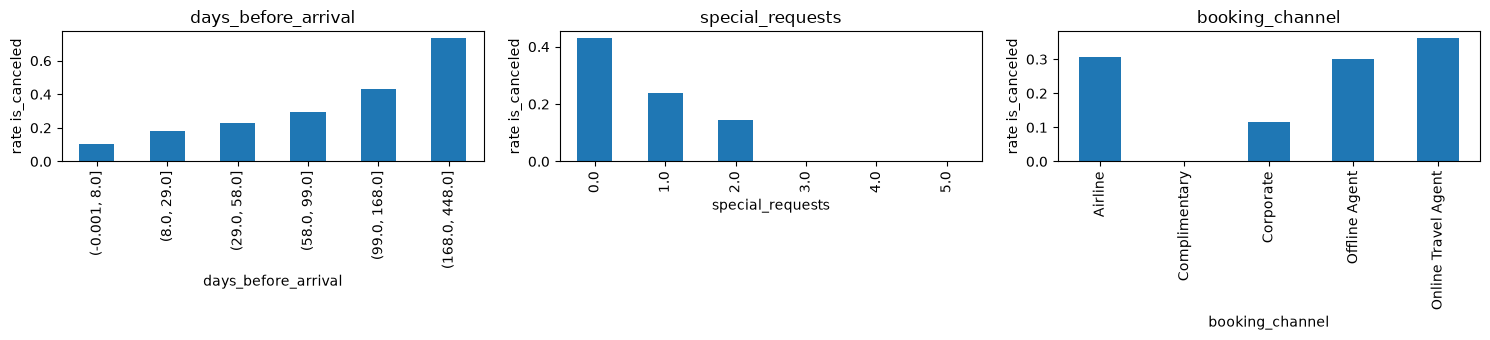

In [10]:
print(train_df[CFG.TARGET].value_counts(normalize=True).round(3))
target_rate(train_df, ['days_before_arrival', 'special_requests', 'booking_channel'], bins={'days_before_arrival': 6})

#### Insights

> Kelas tidak seimbang ringan, dan tiga fitur ini paling jelas memisahkan kelas.

- Sekitar 32,8% pemesanan batal. Macro F1 memberi bobot sama ke dua kelas, jadi threshold perlu dicari, bukan selalu 0,5.
- Lead time naik hampir monoton: rasio batal 10,1% di kelompok lead time terpendek dan 73,8% di kelompok di atas 168 hari. Hubungannya tidak linear, sehingga satu bobot per fitur tidak cukup.
- `special_requests` menurunkan peluang batal: 43,2% tanpa permintaan, 23,8% dengan 1, 14,3% dengan 2, dan tidak ada yang batal dari 563 pemesanan dengan 3 permintaan atau lebih.
- Kanal sangat berpengaruh: Complimentary 0%, Corporate 11,5%, Offline Agent 30,2%, Online Travel Agent 36,4%.

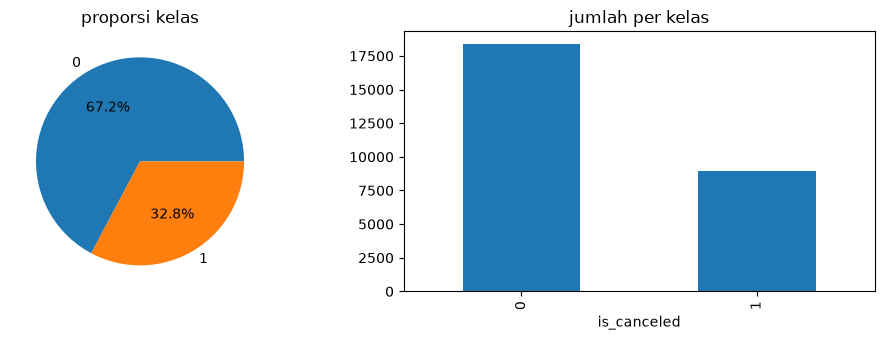

In [11]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
train_df[CFG.TARGET].value_counts().plot.pie(ax=axes[0], autopct='%.1f%%', ylabel='', title='proporsi kelas')
train_df[CFG.TARGET].value_counts().plot.bar(ax=axes[1], title='jumlah per kelas')
plt.tight_layout()
plt.show()

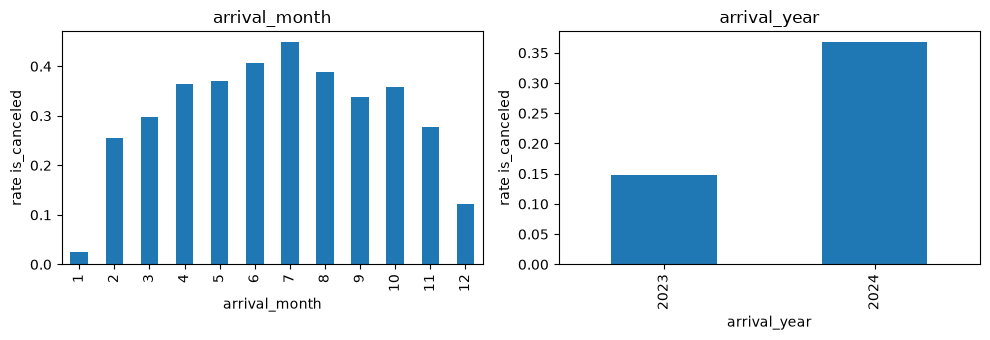

In [12]:
target_rate(train_df, ['arrival_month', 'arrival_year'])

#### Insights

> Ada pola musiman dan pergeseran antartahun.

- Rasio batal terendah di Januari (2,6%) dan Desember (12,1%), tertinggi di Juli (44,8%). Polanya naik lalu turun, jadi bulan lebih cocok di-encode melingkar (sin dan cos) atau di-one-hot, bukan dipakai sebagai angka biasa.
- Tahun 2023 hanya 14,7% batal sedangkan 2024 mencapai 36,7%. Posisi waktu (indeks hari kedatangan) karena itu dipakai sebagai fitur.

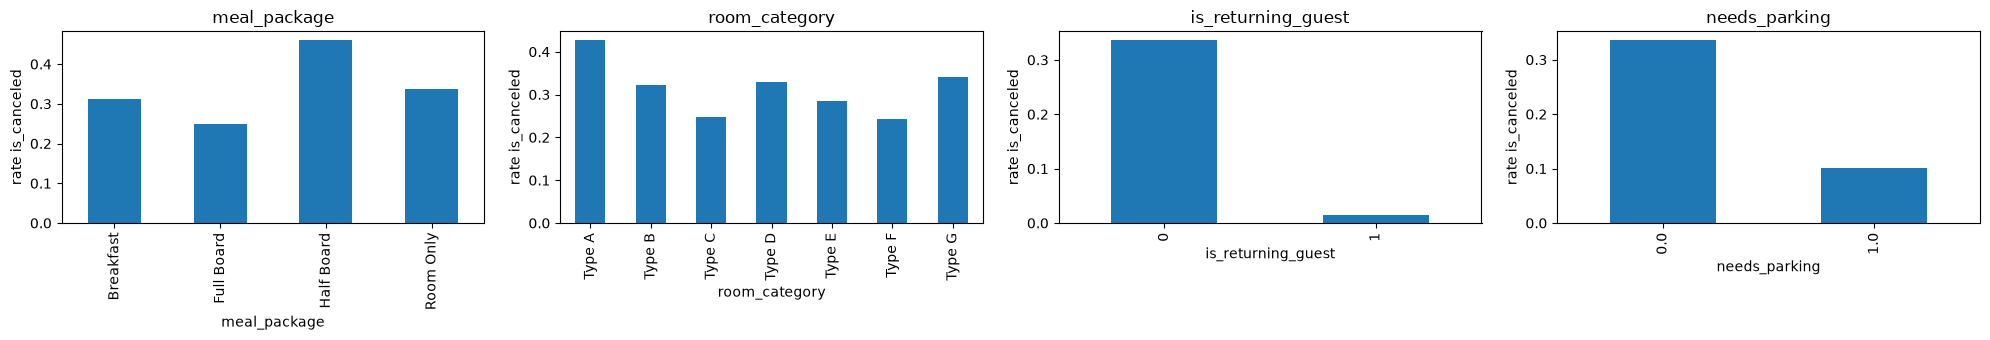

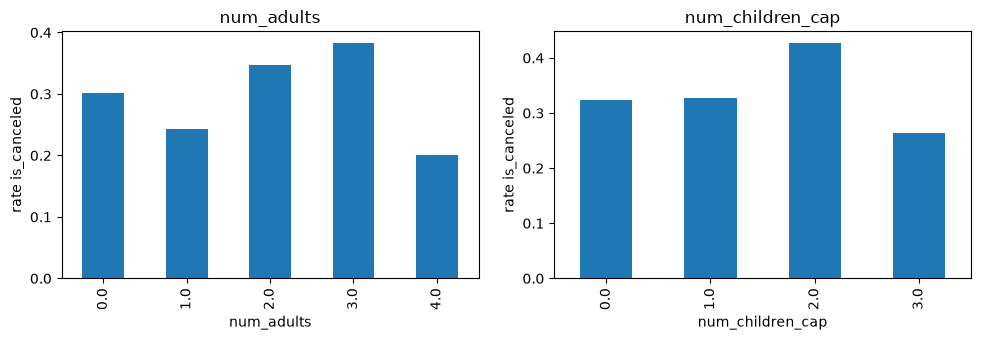

In [13]:
target_rate(train_df, ['meal_package', 'room_category', 'is_returning_guest', 'needs_parking'])
target_rate(train_df.assign(num_children_cap=train_df['num_children'].clip(upper=3)), ['num_adults', 'num_children_cap'])

#### Insights

> Beberapa fitur diskrit punya pola tidak monoton.

- Tamu yang pernah menginap hampir tidak pernah batal (1,5% dibanding 33,6%).
- `num_adults`: 24,2% untuk 1 dewasa, 34,8% untuk 2, dan 38,3% untuk 3. `num_children`: 32,4% tanpa anak dan 42,7% untuk 2 anak. Polanya tidak linear sehingga one-hot per nilai lebih tepat daripada satu bobot untuk angka mentah.

In [14]:
lead_group = pd.cut(train_df['days_before_arrival'], [-1, 29, 99, 168, 1000], labels=['0-29', '30-99', '100-168', '>168'])
train_df.pivot_table(index=lead_group, columns='arrival_year', values=CFG.TARGET, aggfunc='mean', observed=True).round(3)

arrival_year,2023,2024
days_before_arrival,,
0-29,0.054,0.171
30-99,0.118,0.293
100-168,0.355,0.441
>168,0.476,0.763


#### Insights

> Pengaruh lead time bergantung pada tahun kedatangan.

- Untuk lead time di atas 168 hari, rasio batal 47,6% pada 2023 dan 76,3% pada 2024. Untuk lead time sampai 29 hari, 5,4% pada 2023 dan 17,1% pada 2024.
- Pengaruh satu fitur yang berubah menurut fitur lain tidak bisa ditangkap oleh model linear biasa. Karena itu dipakai fitur interaksi dan sel dua dimensi.

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [15]:
def missing(train, test):
    features = test.columns.drop(CFG.ID_COLUMN)
    table = pd.DataFrame({'train': train[features].isna().mean() * 100,
                          'test': test[features].isna().mean() * 100}).round(2)
    return table[table.sum(axis=1) > 0]

def duplicates(df):
    features = df.columns.drop([CFG.ID_COLUMN, CFG.TARGET])
    labels = df.groupby(list(features), dropna=False)[CFG.TARGET].nunique()
    return pd.Series({'baris duplikat': df.duplicated(subset=list(features) + [CFG.TARGET]).sum(),
                      'fitur sama, label beda': (labels > 1).sum()})

In [16]:
missing(train_df, test_df)

,train,test
num_adults,2.96,2.63
num_children,11.09,10.91
meal_package,6.43,6.46
needs_parking,3.95,3.61
room_category,3.66,3.54
days_before_arrival,4.10,4.24
nightly_rate_idr,7.45,7.89
special_requests,9.13,8.66


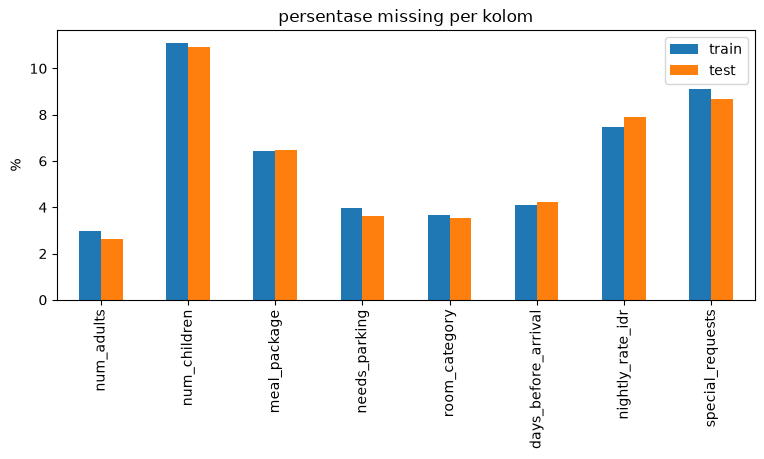

In [17]:
missing(train_df, test_df).plot.bar(figsize=(9, 3.5), title='persentase missing per kolom')
plt.ylabel('%')
plt.show()

In [18]:
nights = train_df['weekend_nights'] + train_df['weekday_nights']
print(duplicates(train_df))
pd.Series({'num_adults = 0 (train)': (train_df['num_adults'] == 0).sum(),
           'num_adults = 0 (test)': (test_df['num_adults'] == 0).sum(),
           'nightly_rate_idr = 0': (train_df['nightly_rate_idr'] == 0).sum(),
           'total malam = 0': (nights == 0).sum(),
           'nilai negatif': int((train_df.select_dtypes('number') < 0).sum().sum())},
          name='jumlah baris')

baris duplikat            64
fitur sama, label beda     2
dtype: int64


num_adults = 0 (train)    106
num_adults = 0 (test)      22
nightly_rate_idr = 0      413
total malam = 0            64
nilai negatif               0
Name: jumlah baris, dtype: int64

#### Insights

> Ada missing value, duplikat, dan nilai tidak valid yang perlu ditangani di preprocessing.

- Missing ada di 8 kolom dengan porsi 3,0% sampai 11,1% (terbanyak `num_children` 11,1%, `special_requests` 9,1%, `nightly_rate_idr` 7,4%). Porsinya mirip di train dan test, jadi imputasi harus sama untuk keduanya.
- Ada 64 baris duplikat persis. Kalau dibiarkan, baris yang sama bisa masuk data latih dan validasi sekaligus sehingga skor validasi terlalu optimis.
- Booking tanpa orang dewasa (`num_adults = 0`) tidak masuk akal, ada 106 baris di train dan 22 di test.
- Harga 0 ada 413 baris dan hampir tidak pernah batal (sekitar 0,7%), jadi bukan kesalahan. Tidak ada nilai negatif.

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [19]:
# dedupe tidak mempelajari statistik apa pun, jadi dilakukan sebelum split supaya duplikat tidak bocor ke validasi
train_clean = clean_train(train_df)
y_clean = train_clean[CFG.TARGET].to_numpy()

train_set, val_set = train_test_split(train_clean, test_size=CFG.TEST_SIZE, stratify=y_clean, random_state=CFG.SEED)
y_train, y_val = train_set[CFG.TARGET].to_numpy(), val_set[CFG.TARGET].to_numpy()

# lima fold stratified untuk OOF, dipakai untuk memilih threshold dan skor di bagian Improvements
folds = stratified_kfold(y_clean, n_splits=CFG.N_FOLDS, seed=CFG.CV_SEED)

pd.Series({'train_clean': len(train_clean), 'train_set': len(train_set), 'val_set': len(val_set), 'test': len(test_df)})

train_clean    27309
train_set      21847
val_set         5462
test            6844
dtype: int64

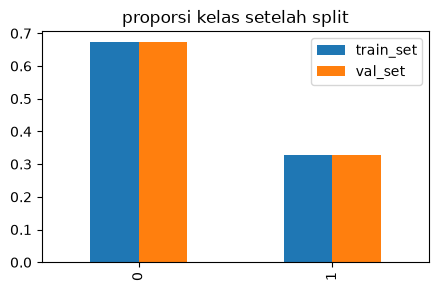

In [20]:
pd.DataFrame({'train_set': pd.Series(y_train).value_counts(normalize=True),
              'val_set': pd.Series(y_val).value_counts(normalize=True)}).plot.bar(figsize=(5, 3), title='proporsi kelas setelah split')
plt.show()

#### Insights

> Holdout 20% stratified setelah dedupe, dan 5-fold OOF untuk skor akhir.

- Dedupe dilakukan sebelum split. Langkah ini tidak mempelajari statistik apa pun, dan mencegah baris yang sama muncul di data latih dan validasi sekaligus.
- Split 80:20 memakai `stratify` sehingga proporsi kelas batal sama (sekitar 32,8%) di `train_set` dan `val_set`.
- Semua statistik preprocessing (median, batas bin, mean, std, level kategori) dihitung dari data latih saja, lalu diterapkan ke validasi dan test.
- Skor akhir dan threshold memakai 5-fold OOF (seed 42) pada `train_clean`. Di tiap fold, preprocessing dan model di-fit ulang hanya pada fold latih.

In [21]:
# ringkas hasil OOF dan jika threshold tidak diberikan, dipilih threshold dengan Macro F1 OOF tertinggi
def report(name, oof, threshold=None):
    if threshold is None:
        threshold, score = best_threshold(y_clean, oof)
    else:
        score = macro_f1(y_clean, (oof >= threshold).astype(int))
    per_fold = fold_scores(y_clean, oof, folds, threshold)
    return dict(model=name, threshold=threshold, oof_macro_f1=round(score, 4),
                fold_mean=round(float(per_fold.mean()), 4), fold_std=round(float(per_fold.std()), 4))

---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

Contoh kode di bagian ini dijalankan pada `train_set` (statistik dipelajari dari sini) dan `val_set` (hanya ditransformasi), supaya terlihat bahwa tidak ada informasi dari data validasi yang masuk. Urutan lengkapnya digabung di class `LRPreprocessor` dan dipanggil di bagian Preparation Pipeline.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [22]:
categorical = ['meal_package', 'room_category', 'booking_channel']
features = train_df.columns.drop([CFG.ID_COLUMN, CFG.TARGET])
numeric = [c for c in features if c not in categorical]

print(f'{len(features)} fitur dipakai ({len(numeric)} numerik, {len(categorical)} kategorikal)')
print('numerik     :', numeric)
print('kategorikal :', categorical)
print('dibuang     : id (hanya pengenal)')

17 fitur dipakai (14 numerik, 3 kategorikal)
numerik     : ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']
kategorikal : ['meal_package', 'room_category', 'booking_channel']
dibuang     : id (hanya pengenal)


#### Insights

> Semua 17 fitur dipertahankan, seleksi diserahkan ke regularisasi.

- Kolom `id` hanya pengenal sehingga dibuang. Tidak ada fitur yang dibuang manual.
- Pemilihan fitur dilakukan model lewat regularisasi, yang mengecilkan bobot fitur yang tidak berguna. Pada L1, bobot itu menjadi tepat nol.

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

Numerik diisi median dari data latih dan ditambah kolom indikator `<kolom>_missing`. Kategorikal yang kosong dijadikan level `Missing`. Kategori yang kurang dari 20 baris di data latih digabung menjadi `Other`.

In [23]:
medians = train_set[numeric].median()
before = train_set[numeric].isna().sum()
after_train = train_set[numeric].fillna(medians).isna().sum().sum()
after_val = val_set[numeric].fillna(medians).isna().sum().sum()

display(pd.DataFrame({'kosong_train_set': before, 'median_train': medians.round(2)})[before > 0])
print('sisa kosong setelah imputasi: train_set', int(after_train), '| val_set', int(after_val))

,kosong_train_set,median_train
num_adults,657,2.0
num_children,2450,0.0
needs_parking,851,0.0
days_before_arrival,895,58.0
nightly_rate_idr,1585,1644000.0
special_requests,1977,0.0


sisa kosong setelah imputasi: train_set 0 | val_set 0


#### Insights

> Numerik diisi median dan kategorikal dijadikan level `Missing`, keduanya dari data latih.

- Median dipilih karena fitur seperti `nightly_rate_idr` dan `days_before_arrival` miring ke kanan, sehingga rata-rata terseret nilai besar.
- Median dari `train_set` dipakai juga untuk `val_set` dan test, jadi tidak ada informasi validasi yang masuk.
- Kolom indikator missing dibuat supaya model tahu nilai itu sebelumnya kosong, karena pola kosong bisa membawa informasi.
- Baris tidak dibuang karena missing tersebar di banyak kolom.

### Duplicates

This part covers repeated records.

In [24]:
feature_cols = [c for c in train_df.columns if c != CFG.ID_COLUMN]
print(f'baris train sebelum: {len(train_df):,} | duplikat persis: {int(train_df.duplicated(subset=feature_cols).sum())} | sesudah: {len(train_clean):,}')
assert not train_clean.duplicated(subset=feature_cols).any()
print('test tidak diubah:', len(test_df), 'baris')

baris train sebelum: 27,373 | duplikat persis: 64 | sesudah: 27,309
test tidak diubah: 6844 baris


#### Insights

> Baris duplikat (fitur dan label sama) dibuang, yang pertama disimpan.

- Hanya 64 baris (0,23%) yang dibuang, dan dilakukan di bagian Training and Validation Split sebelum data dibagi.
- Test tidak dibuang barisnya karena setiap id wajib diprediksi.

### Outliers

This part covers values far from the rest of the data.

Baris outlier tidak dibuang. Dampaknya dikecilkan dengan `log1p` untuk fitur non-negatif yang miring (skewness di atas 1) dan dengan binning, yang membuat nilai ekstrem hanya jatuh ke bin paling ujung.

,skewness,diterapkan_log1p
prior_cancellations,26.39,True
prior_completed_bookings,19.34,True
is_returning_guest,6.04,False
needs_parking,5.60,False
num_children,5.18,True
weekday_nights,1.65,True
days_before_arrival,1.35,True
special_requests,1.19,True
nightly_rate_idr,0.76,False
weekend_nights,0.75,False


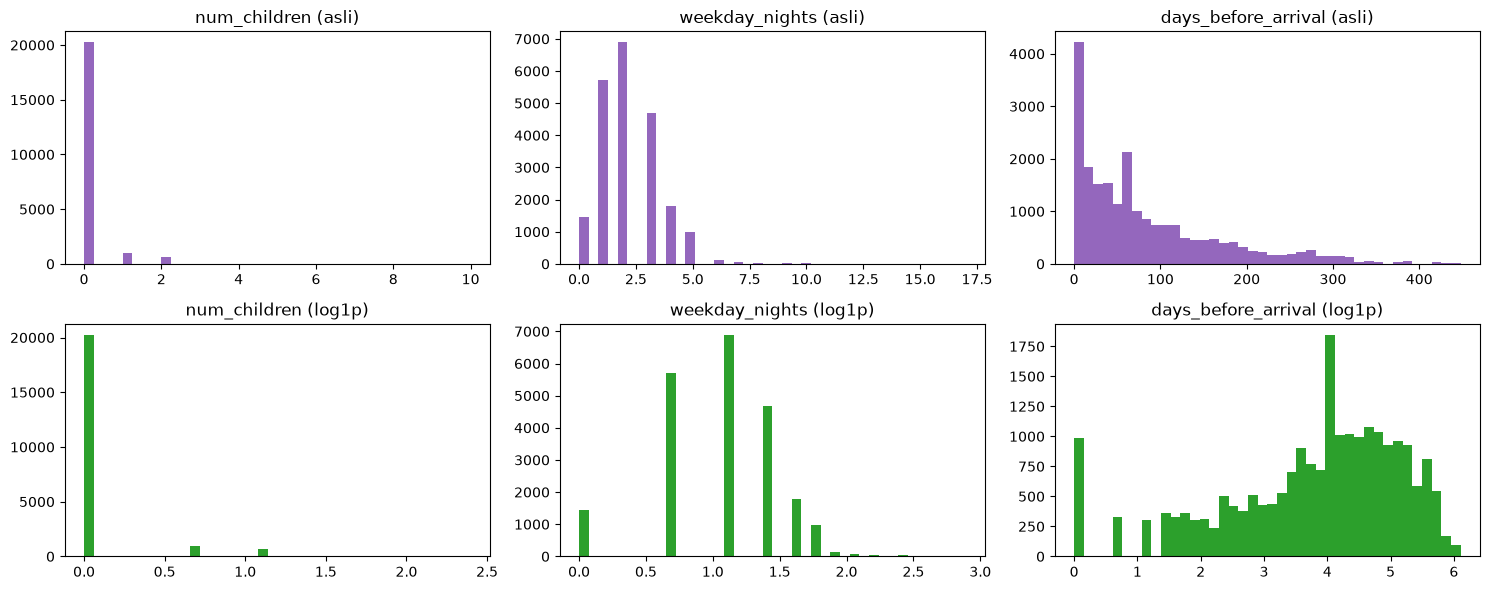

In [25]:
filled = train_set[numeric].fillna(medians)
skew = filled.skew()
is_logged = (filled.min() >= 0) & (filled.nunique() > 2) & (skew > 1.0)
display(pd.DataFrame({'skewness': skew.round(2), 'diterapkan_log1p': is_logged}).sort_values('skewness', ascending=False))

shown = list(is_logged[is_logged].index[:3])
figure, axes = plt.subplots(2, len(shown), figsize=(5 * len(shown), 6), squeeze=False)
for j, column in enumerate(shown):
    axes[0, j].hist(filled[column], bins=40, color='tab:purple')
    axes[0, j].set_title(f'{column} (asli)')
    axes[1, j].hist(np.log1p(filled[column]), bins=40, color='tab:green')
    axes[1, j].set_title(f'{column} (log1p)')
plt.tight_layout()
plt.show()

#### Insights

> Outlier tidak dibuang, nilai ekstrem dikecilkan dengan `log1p` dan binning.

- Nilai ekstrem seperti `prior_cancellations` sampai 13 atau `days_before_arrival` sampai 448 masuk akal pada data pemesanan, dan lead time panjang justru menandakan risiko batal tinggi.
- Fitur biner tidak ikut di-log karena hanya bernilai 0 dan 1.
- Setelah `log1p`, fitur yang miring menjadi lebih simetris sehingga satu bobot linear tidak lagi didominasi beberapa nilai besar.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [26]:
fixed = mark_invalid(train_set)
n_zero_adults = int((train_set['num_adults'] == 0).sum())
n_new_missing = int(fixed['num_adults'].isna().sum() - train_set['num_adults'].isna().sum())
print(f'num_adults = 0 di train_set: {n_zero_adults} baris, menjadi kosong setelah mark_invalid: {n_new_missing} baris')

free = (train_df['nightly_rate_idr'] == 0).rename('harga = 0')
display(pd.crosstab(free, train_df['booking_channel']))
print(f'rasio batal pada harga 0: {train_df.loc[free, CFG.TARGET].mean():.4f} dari {int(free.sum())} baris')

num_adults = 0 di train_set: 92 baris, menjadi kosong setelah mark_invalid: 92 baris


booking_channel,Airline,Complimentary,Corporate,Offline Agent,Online Travel Agent
harga = 0,,,,,
False,88,34,1513,7960,17365
True,0,267,0,0,146


rasio batal pada harga 0: 0.0073 dari 413 baris


#### Insights

> `num_adults = 0` dianggap data error, diubah jadi missing lalu diisi median.

- Booking butuh minimal satu dewasa, jadi nilai 0 tidak masuk akal.
- Harga 0 bukan kesalahan. Pemesanan gratis hampir tidak pernah batal (sekitar 0,7%), sehingga nilai 0 dipertahankan dan ditandai dengan fitur `is_free`.
- 64 baris dengan total malam 0 dibiarkan karena jumlahnya sangat kecil.

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

| Fitur | Cara hitung | Alasan |
|---|---|---|
| `total_nights` | malam akhir pekan + malam hari kerja | lama menginap |
| `total_guests` | dewasa + anak | ukuran rombongan |
| `is_free` | harga = 0 | pemesanan gratis hampir tidak pernah batal |
| `rate_per_guest` | harga / jumlah tamu | harga per orang |
| `arrival_weekday`, `arrival_dayofyear` | dari tanggal kedatangan | pola mingguan dan musiman |
| `arrival_index` | hari sejak 2023-01-01 | posisi waktu, karena rasio batal bergeser dari waktu ke waktu |

In [27]:
constructed = add_features(mark_invalid(train_set))
new_cols = [c for c in constructed.columns if c not in train_set.columns]
display(constructed[new_cols].head())

,total_nights,total_guests,is_free,rate_per_guest,arrival_weekday,arrival_dayofyear,arrival_index
23158,5,2.0,0.0,817000.0,5.0,328.0,692.0
6939,1,2.0,0.0,739000.0,5.0,174.0,538.0
22591,2,2.0,0.0,722000.0,3.0,53.0,417.0
16914,4,2.0,0.0,368500.0,0.0,78.0,442.0
16072,1,2.0,0.0,771000.0,0.0,246.0,610.0


#### Insights

> Fitur turunan menambah informasi yang tidak ada di kolom mentah.

- `arrival_index` menaruh tanggal kedatangan pada satu sumbu waktu, karena rasio batal 2023 (14,7%) jauh di bawah 2024 (36,7%).
- `rate_per_guest` dan `total_nights` menggabungkan beberapa kolom menjadi ukuran yang lebih dekat ke keputusan tamu.
- `is_free` menandai pemesanan gratis yang hampir tidak pernah batal.

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

Dua langkah penskalaan. `log1p` untuk fitur miring, lalu standardisasi (z-score) `(x - mean) / std` dengan mean dan std dari data latih. Standardisasi wajib untuk model berbasis gradien karena fitur berskala jutaan (`nightly_rate_idr`) membuat langkah gradient descent tidak seimbang dan konvergensi lambat. Regularisasi juga baru adil kalau semua fitur berskala sama. Fitur waktu yang berulang memakai encoding siklik sin dan cos, supaya Desember dan Januari tetap berdekatan.

In [28]:
demo = ['days_before_arrival', 'nightly_rate_idr']
x_train = train_set[demo].fillna(medians[demo])
x_val = val_set[demo].fillna(medians[demo])

# standardisasi dengan mean dan std dari train_set, lalu diterapkan ke val_set
mean, std = x_train.mean(), x_train.std()
z_train, z_val = (x_train - mean) / std, (x_val - mean) / std
display(pd.DataFrame({'mean_asli': x_train.mean(), 'std_asli': x_train.std(),
                      'mean_z_train': z_train.mean(), 'std_z_train': z_train.std(),
                      'mean_z_val': z_val.mean(), 'std_z_val': z_val.std()}).round(3))


# jarak dua bulan pada lingkaran sin dan cos
def cyclic_distance(a, b, period=12):
    angle = lambda m: 2 * np.pi * m / period
    return float(np.hypot(np.sin(angle(a)) - np.sin(angle(b)), np.cos(angle(a)) - np.cos(angle(b))))


print(f'jarak bulan 12 ke 1: angka biasa {abs(12 - 1)}, siklik {cyclic_distance(12, 1):.3f}')
print(f'jarak bulan 1 ke 2 : angka biasa {abs(1 - 2)}, siklik {cyclic_distance(1, 2):.3f}')

,mean_asli,std_asli,mean_z_train,std_z_train,mean_z_val,std_z_val
days_before_arrival,84.314,84.384,-0.0,1.0,-0.010,0.994
nightly_rate_idr,1710663.432,566102.490,-0.0,1.0,0.013,1.000


jarak bulan 12 ke 1: angka biasa 11, siklik 0.518
jarak bulan 1 ke 2 : angka biasa 1, siklik 0.518


#### Insights

> Fitur di-standardisasi dengan statistik data latih, dan bulan di-encode melingkar.

- Setelah standardisasi, mean dan std `train_set` tepat 0 dan 1, sedangkan `val_set` hanya mendekati karena memakai statistik data latih. Itu memang yang diinginkan.
- Jarak Desember ke Januari pada encoding siklik sama dengan jarak antar bulan berdekatan lainnya, padahal sebagai angka biasa jaraknya 11.

### Encoding

This part covers the numeric representation of categorical attributes.

Cara mengubah atribut menjadi angka:

- **One-hot kategorikal.** `meal_package`, `room_category`, dan `booking_channel`. Kategori paling sering dijadikan acuan dan tidak dibuat kolomnya, supaya kolom tidak kolinear dengan bias.
- **One-hot diskrit.** `special_requests`, `arrival_month`, `num_adults`, dan `num_children` di-one-hot per nilai, dengan nilai besar digabung ke batas atas. Efek nilai diskrit sering tidak linear.
- **Binning berbasis target.** Tujuh fitur numerik dipotong menjadi 16 kelompok dengan pemisahan biner yang paling menurunkan impuritas Gini terhadap target (minimal 300 baris per kelompok), lalu di-one-hot. Cara ini diadaptasi dari kriteria pemisahan CART [1]. Dibanding bin kuantil, batasnya jatuh di tempat rasio batal benar-benar berubah.
- **Interaksi.** 14 fitur terpilih dikalikan dengan seluruh kolom lain, supaya model linear bisa menangkap pengaruh yang saling bergantung. Hasil perkaliannya distandardisasi ulang.

In [29]:
print('Kategori room_category pada train_set (kosong menjadi Missing, kategori jarang menjadi Other di preprocessor):')
display(train_set['room_category'].fillna('Missing').value_counts().to_frame('baris'))

for column, cap in CFG.SR.items():
    values = train_set[column].fillna(train_set[column].median()).clip(upper=cap)
    print(column, '-> rasio batal per nilai:', train_set.groupby(values)[CFG.TARGET].mean().round(3).to_dict())

Kategori room_category pada train_set (kosong menjadi Missing, kategori jarang menjadi Other di preprocessor):


,baris
room_category,
Type B,16334
Type G,3476
Missing,812
Type A,562
Type D,414
Type C,142
Type F,100
Type E,7


special_requests -> rasio batal per nilai: {0.0: 0.427, 1.0: 0.238, 2.0: 0.145, 3.0: 0.0}
arrival_month -> rasio batal per nilai: {1: 0.026, 2: 0.261, 3: 0.305, 4: 0.359, 5: 0.369, 6: 0.398, 7: 0.452, 8: 0.388, 9: 0.341, 10: 0.355, 11: 0.282, 12: 0.124}
num_adults -> rasio batal per nilai: {0.0: 0.283, 1.0: 0.24, 2.0: 0.349, 3.0: 0.374}
num_children -> rasio batal per nilai: {0.0: 0.325, 1.0: 0.323, 2.0: 0.427, 3.0: 0.294}


metode: target | batas bin (hari): [5.5, 15.5, 27.5, 46.5, 57.5, 92.5, 112.5, 150.5, 166.5, 186.5, 231.5, 251.5, 274.5, 297.5, 322.5]


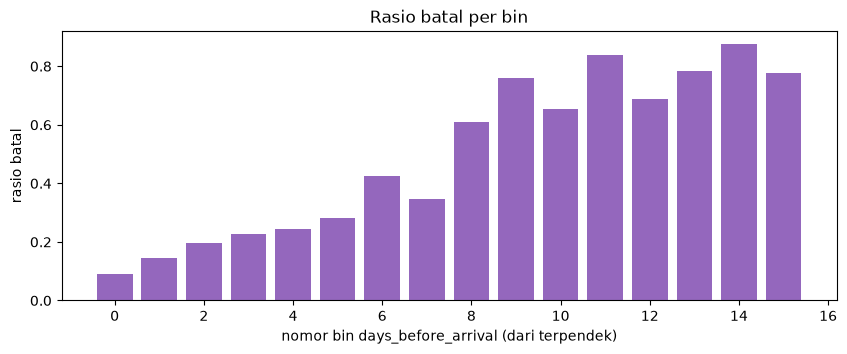

In [30]:
# contoh binning untuk days_before_arrival sesuai BIN_PARAMS
x = train_set['days_before_arrival'].fillna(medians['days_before_arrival']).to_numpy()
t = train_set[CFG.TARGET].to_numpy()
n_bins = CFG.BIN_PARAMS['n_bins']
if CFG.BIN_PARAMS['bin_method'] == 'target':
    edges = target_edges(x, t, n_bins, CFG.BIN_PARAMS['bin_min_leaf'])
else:
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1)[1:-1]))
bin_id = np.searchsorted(edges, x, side='right')
stats = pd.DataFrame({'bin': bin_id, 'batal': t}).groupby('bin')['batal'].agg(['mean', 'size'])
print('metode:', CFG.BIN_PARAMS['bin_method'], '| batas bin (hari):', np.round(edges, 1).tolist())

figure, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(stats.index, stats['mean'], color='tab:purple')
ax.set_xlabel('nomor bin days_before_arrival (dari terpendek)')
ax.set_ylabel('rasio batal')
ax.set_title('Rasio batal per bin')
plt.show()

In [31]:
rises = int((np.diff(stats['mean'].to_numpy()) > 0).sum())
display(Markdown(
    f'#### Insights\n\n'
    f'> Rasio batal per bin berubah dari {stats["mean"].iloc[0]:.3f} pada bin lead time terpendek menjadi {stats["mean"].iloc[-1]:.3f} pada bin terpanjang, '
    f'dan naik di {rises} dari {len(stats) - 1} perpindahan antar bin berurutan.\n\n'
    f'- Satu bobot linear untuk `days_before_arrival` hanya bisa menggambar garis lurus, sedangkan satu bobot per bin bisa mengikuti bentuk yang tidak linear ini.\n'
    f'- Kategori jarang digabung menjadi `Other` supaya kolom one-hot tidak dibuat untuk level dengan sangat sedikit baris.'))

#### Insights

> Rasio batal per bin berubah dari 0.092 pada bin lead time terpendek menjadi 0.775 pada bin terpanjang, dan naik di 11 dari 15 perpindahan antar bin berurutan.

- Satu bobot linear untuk `days_before_arrival` hanya bisa menggambar garis lurus, sedangkan satu bobot per bin bisa mengikuti bentuk yang tidak linear ini.
- Kategori jarang digabung menjadi `Other` supaya kolom one-hot tidak dibuat untuk level dengan sangat sedikit baris.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

> Reduksi dimensi dilakukan lewat regularisasi L1, bukan PCA.

#### Insights

- PCA tidak dipakai karena mencampur kolom one-hot dan interaksi menjadi komponen yang sulit dibaca, padahal bobot per bin dan per kategori adalah bagian yang bisa dijelaskan.
- Seleksi fitur dilakukan oleh regularisasi. Pada L1, bobot fitur yang tidak berguna menjadi tepat nol, dan jumlah kolom yang tersisa dilaporkan di bagian Modeling dan Error Analysis.

## Class Balance

This part covers the proportion of each class in the training data.

In [32]:
counts = pd.Series(y_train).value_counts().sort_index()
display(pd.DataFrame({'jumlah': counts, 'proporsi': (counts / len(y_train)).round(3)}, index=['tidak batal (0)', 'batal (1)']))
print('Macro F1 jika semua ditebak tidak batal:', round(macro_f1(y_val, np.zeros_like(y_val)), 4))

,jumlah,proporsi
tidak batal (0),NaN,NaN
batal (1),NaN,NaN


Macro F1 jika semua ditebak tidak batal: 0.4021


#### Insights

> Tidak dilakukan oversampling atau undersampling.

- Ketidakseimbangan ringan (sekitar 67:33) dan Macro F1 sudah memberi bobot sama ke dua kelas.
- Ketidakseimbangan ditangani dengan threshold probabilitas yang memaksimalkan Macro F1 pada OOF.
- Resampling merusak kalibrasi probabilitas, padahal bonus cost-sensitive membutuhkan probabilitas yang bisa dipercaya. Untuk kasus itu, ketidakseimbangan ditangani lewat bobot kelas pada log-loss.

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

Hasil akhir preparation adalah matriks numerik `float64` tanpa NaN (`pandas.DataFrame` dengan nama kolom). Model mengubahnya menjadi array NumPy atau CuPy saat training. Bentuk matriksnya diperlihatkan di Preparation Pipeline.

---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

Seluruh langkah di atas digabung dalam class `LRPreprocessor` (`src/preprocessing/lr.py`) dengan dua method. `fit` mempelajari statistik dari data latih dan `transform` menerapkannya ke data lain. Urutannya: tandai nilai janggal, fitur turunan, indikator missing, imputasi median, `log1p`, encoding siklik, binning, one-hot, standardisasi, lalu interaksi dan standardisasi ulang. Kolom yang konstan atau kembar dibuang.

In [33]:
def make_prep():
    return LRPreprocessor(**CFG.PREP_PARAMS)


# device dan dtype bisa ditimpa, parameter lain bisa diganti lewat overrides
def make_model(device=None, dtype=None, **overrides):
    params = {**CFG.LR_PARAMS, **overrides}
    return LogisticRegression(device=device or CFG.DEVICE, dtype=dtype or CFG.DTYPE, **params)


# kelompok sebuah kolom hasil preprocessing berdasarkan namanya
def column_group(name):
    if '*' in name:
        return 'interaksi'
    if '_x_' in name:
        return 'sel dua dimensi'
    if '_bin' in name:
        return 'bin'
    return 'dasar dan one-hot'


# statistik dipelajari dari train_set saja, lalu diterapkan ke val_set dan test
prep = make_prep().fit(train_set)
X_train, X_val, X_test = prep.transform(train_set), prep.transform(val_set), prep.transform(test_df)

display(pd.Series({'X_train': X_train.shape, 'X_val': X_val.shape, 'X_test': X_test.shape}).to_frame('bentuk'))
print('NaN train/val/test:', int(X_train.isna().sum().sum()), '/', int(X_val.isna().sum().sum()), '/', int(X_test.isna().sum().sum()))
display(pd.Series([column_group(c) for c in X_train.columns]).value_counts().to_frame('jumlah_kolom'))

,bentuk
X_train,"(21847, 2032)"
X_val,"(5462, 2032)"
X_test,"(6844, 2032)"


NaN train/val/test: 0 / 0 / 0


,jumlah_kolom
interaksi,1881
bin,83
dasar dan one-hot,68


#### Insights

> Matriks akhir berisi ribuan kolom dan sebagian besar adalah interaksi.

- Preprocessor hanya melihat data yang diberikan ke `fit`, jadi validasi dan test tidak ikut membentuk batas bin, median, mean, dan std.
- Matriks `X_train`, `X_val`, dan `X_test` dipakai Logistic Regression. Untuk k-fold atau training final, `make_prep()` dipanggil ulang dengan data fit yang baru.

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

In [34]:
# Write your code here
# Pakai matriks dari Preparation Pipeline: X_train, X_val, X_test (y_train, y_val)
# Simpan skor validasi: RESULTS['KNN'] = macro_f1(y_val, pred_val)

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [35]:
# Write your code here
# Pakai matriks dari Preparation Pipeline: X_train, X_val, X_test (y_train, y_val)
# Simpan skor validasi: RESULTS['DTL'] = macro_f1(y_val, pred_val)

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

`LogisticRegression` from scratch (`src/models/logistic_regression.py`) mendukung regularisasi **L1, L2, dan Elastic Net**, bobot kelas, dan training di CPU atau GPU. Probabilitas batal untuk satu pemesanan dengan fitur $x$:

$$P(y = 1 \mid x) = \sigma(z), \qquad z = b + w^\top x, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}$$

Fungsi objektif disamakan dengan scikit-learn supaya nilai `C` bisa dibandingkan langsung, lalu dibagi $C \cdot S$:

$$J(w, b) = \frac{1}{S}\sum_i s_i \big[\log(1 + e^{z_i}) - y_i z_i\big] + \frac{1 - \rho}{2\,C\,S}\|w\|_2^2 + \frac{\rho}{C\,S}\|w\|_1$$

Dengan $s_i$ bobot sampel, $S = \sum_i s_i$, $\rho = 0$ untuk L2, $\rho = 1$ untuk L1, dan $\rho$ = `l1_ratio` untuk Elastic Net. Bias tidak diregularisasi. Training memakai solver **FISTA** (gradient descent terakselerasi dengan proximal step untuk L1), yang dijelaskan di bagian Referensi [2], [3].

Prediksi 1 (batal) jika $P(y = 1 \mid x) \ge \tau$, dengan threshold $\tau$ dipilih dari OOF yang memberi Macro F1 tertinggi.

Model di notebook ini memakai **L1** dengan `C = 0,1`. Ketiga regularisasi dicoba pada `train_set` dengan `C` yang sama untuk melihat perbedaannya.

In [36]:
RESULTS = {}
LABEL = {'l1': 'L1', 'l2': 'L2', 'elasticnet': 'Elastic Net'}
holdout_rows, holdout_models = [], {}

for penalty in ['l1', 'l2', 'elasticnet']:
    start = time.perf_counter()
    model = make_model(penalty=penalty).fit(X_train, y_train)
    proba = model.predict_proba(X_val)
    pred_val = (proba >= CFG.THRESHOLD).astype(int)
    RESULTS[f'LR {LABEL[penalty]}'] = macro_f1(y_val, pred_val)
    holdout_models[penalty] = model
    holdout_rows.append(dict(regularisasi=LABEL[penalty], iterasi=model.n_iter_, konvergen=bool(model.converged_),
                             bobot_tidak_nol=int((model.coef_ != 0).sum()), macro_f1_val=round(RESULTS[f'LR {LABEL[penalty]}'], 4),
                             logloss_val=round(float(log_loss(y_val, proba)), 4), waktu_detik=round(time.perf_counter() - start, 1)))
    print('selesai', LABEL[penalty])

# model utama notebook ini sesuai LR_PARAMS
RESULTS['Logistic Regression'] = RESULTS[f"LR {LABEL[CFG.LR_PARAMS['penalty']]}"]
display(pd.DataFrame(holdout_rows).set_index('regularisasi'))

selesai L1


selesai L2


selesai Elastic Net


,iterasi,konvergen,bobot_tidak_nol,macro_f1_val,logloss_val,waktu_detik
regularisasi,,,,,,
L1,329,True,989,0.8327,0.3413,70.9
L2,1247,True,2032,0.8272,0.3588,195.9
Elastic Net,526,True,1186,0.8289,0.3452,113.4


In [37]:
main_penalty = CFG.LR_PARAMS['penalty']
main = holdout_models[main_penalty]
n_cols = len(main.coef_)
best_name = max((k for k in RESULTS if k.startswith('LR ')), key=RESULTS.get)
display(Markdown(
    f'#### Insights\n\n'
    f'> Pada holdout (threshold {CFG.THRESHOLD}), model utama {LABEL[main_penalty]} mendapat Macro F1 {RESULTS["Logistic Regression"]:.4f}.\n\n'
    f'- Macro F1 holdout: ' + ', '.join(f'{k} {v:.4f}' for k, v in RESULTS.items() if k.startswith('LR ')) + f'. Yang tertinggi adalah {best_name}.\n'
    f'- Model utama memakai {int((main.coef_ != 0).sum())} dari {n_cols} kolom. '
    f'L1 dan Elastic Net bisa membuat bobot tepat nol (seleksi fitur otomatis), sedangkan L2 hanya mengecilkan bobot.\n'
    f'- Skor holdout hanya satu pembagian data, jadi selisih kecil antar regularisasi belum tentu berarti. Skor yang dijadikan acuan adalah OOF 5-fold di bagian Improvements.'))

#### Insights

> Pada holdout (threshold 0.45), model utama L1 mendapat Macro F1 0.8327.

- Macro F1 holdout: LR L1 0.8327, LR L2 0.8272, LR Elastic Net 0.8289. Yang tertinggi adalah LR L1.
- Model utama memakai 989 dari 2032 kolom. L1 dan Elastic Net bisa membuat bobot tepat nol (seleksi fitur otomatis), sedangkan L2 hanya mengecilkan bobot.
- Skor holdout hanya satu pembagian data, jadi selisih kecil antar regularisasi belum tentu berarti. Skor yang dijadikan acuan adalah OOF 5-fold di bagian Improvements.

## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

In [38]:
# Write your code here
# Pakai matriks dari Preparation Pipeline: X_train, X_val, X_test (y_train, y_val)
# Simpan skor validasi: RESULTS['SVM'] = macro_f1(y_val, pred_val)

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [39]:
# Write your code here
# Pakai matriks dari Preparation Pipeline: X_train, X_val, X_test (y_train, y_val)
# Simpan skor validasi: RESULTS['Naive Bayes'] = macro_f1(y_val, pred_val)

## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

,Macro F1 holdout
LR L1,0.8327
Logistic Regression,0.8327
LR Elastic Net,0.8289
LR L2,0.8272


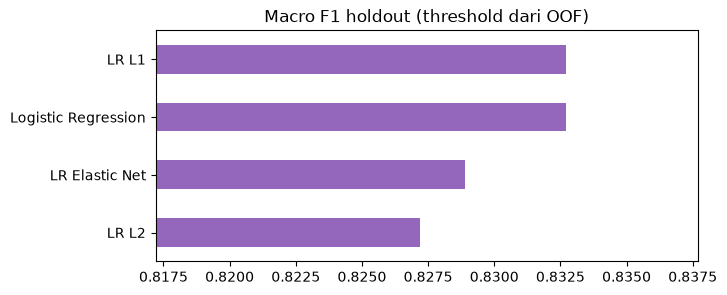

In [40]:
evaluation = pd.Series(RESULTS, name='Macro F1 holdout').round(4).sort_values(ascending=False).to_frame()
display(evaluation)

evaluation['Macro F1 holdout'].sort_values().plot.barh(figsize=(7, 3), color='tab:purple', title='Macro F1 holdout (threshold dari OOF)')
plt.xlim(evaluation['Macro F1 holdout'].min() - 0.01, evaluation['Macro F1 holdout'].max() + 0.005)
plt.show()

#### Insights

> Hanya model Logistic Regression yang diisi di notebook ini, model lain dikerjakan anggota lain.

- Tabel membandingkan tiga jenis regularisasi pada holdout yang sama dan fitur yang sama.
- Perbandingan antar model (KNN, DTL, SVM, Naive Bayes) ada di notebook utama kelompok.

## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

K-Fold Cross Validation pada `train_clean`. Di tiap fold, preprocessing dan model di-fit ulang hanya pada fold latih, dan skor dihitung dari prediksi out-of-fold (OOF).

In [41]:
start = time.perf_counter()
oof = cross_val_proba(make_model, make_prep, train_clean, y_clean, folds)
print(f'waktu validasi silang {time.perf_counter() - start:.0f} detik (device {CFG.DEVICE}, dtype {CFG.DTYPE})')

res_best = report('LR', oof)
res_cfg = report('LR', oof, threshold=CFG.THRESHOLD)
thr_oof = res_best['threshold']
fold_f1 = fold_scores(y_clean, oof, folds, CFG.THRESHOLD)
print('\n======== OOF Logistic Regression ========')
print(f'Macro F1 OOF pada threshold {CFG.THRESHOLD}: {res_cfg["oof_macro_f1"]:.4f}   (diharapkan {CFG.EXPECTED_OOF}, selisih {res_cfg["oof_macro_f1"] - CFG.EXPECTED_OOF:+.4f})')
print(f'threshold terbaik OOF: {thr_oof}   (dipakai: {CFG.THRESHOLD})')
print(f'std per fold: {fold_f1.std():.4f}   (per fold: {np.round(fold_f1, 4).tolist()})')
pred_oof = (oof >= CFG.THRESHOLD).astype(int)
print('confusion matrix OOF [[TN, FP], [FN, TP]]')
print(confusion_matrix(y_clean, pred_oof))
print('F1 kelas 0, kelas 1:', f1_per_class(y_clean, pred_oof).round(4))
if abs(res_cfg['oof_macro_f1'] - CFG.EXPECTED_OOF) > 0.0006:
    print('PERINGATAN: OOF berbeda dari yang diharapkan, periksa versi kode dan library')

waktu validasi silang 736 detik (device cpu, dtype float64)

======== OOF Logistic Regression ========
Macro F1 OOF pada threshold 0.45: 0.8297   (diharapkan 0.8297, selisih +0.0000)
threshold terbaik OOF: 0.45   (dipakai: 0.45)
std per fold: 0.0031   (per fold: [0.833, 0.8329, 0.825, 0.8298, 0.8279])


confusion matrix OOF [[TN, FP], [FN, TP]]
[[16395  1970]
 [ 2110  6834]]
F1 kelas 0, kelas 1: [0.8893 0.7701]


In [42]:
(tn, fp), (fn, tp) = confusion_matrix(y_clean, pred_oof)
f1_0, f1_1 = f1_per_class(y_clean, pred_oof)
display(Markdown(
    f'#### Insights\n\n'
    f'> OOF Macro F1 **{res_cfg["oof_macro_f1"]:.4f}** pada threshold **{CFG.THRESHOLD}** dengan std antar fold {fold_f1.std():.4f}.\n\n'
    f'- F1 kelas tidak batal {f1_0:.4f} dan F1 kelas batal {f1_1:.4f}.\n'
    f'- Kesalahannya terdiri dari {fp} False Positive (tamu yang datang diprediksi batal) dan {fn} False Negative (batal yang tidak terdeteksi).\n'
    f'- Threshold yang dipakai {"sama dengan" if abs(thr_oof - CFG.THRESHOLD) < 1e-9 else "berbeda dari"} threshold terbaik OOF ({thr_oof}).'))

#### Insights

> OOF Macro F1 **0.8297** pada threshold **0.45** dengan std antar fold 0.0031.

- F1 kelas tidak batal 0.8893 dan F1 kelas batal 0.7701.
- Kesalahannya terdiri dari 1970 False Positive (tamu yang datang diprediksi batal) dan 2110 False Negative (batal yang tidak terdeteksi).
- Threshold yang dipakai sama dengan threshold terbaik OOF (0.45).

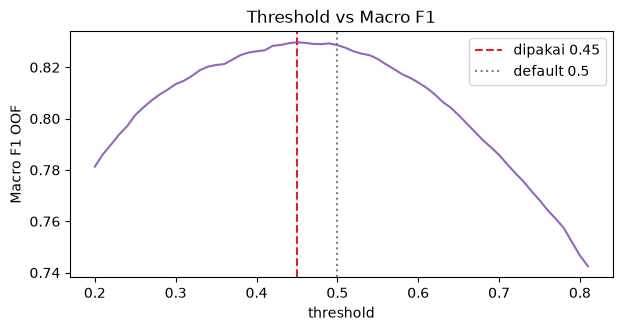

#### Insights

> Threshold terbaik 0.45 memberi Macro F1 0.8297, sedangkan threshold 0,5 memberi 0.8286.

- Dalam rentang 0,03 di kiri dan kanan optimum, skor paling rendah 0.8283, sehingga hasil tidak terlalu sensitif terhadap pergeseran kecil threshold.
- Threshold di bawah 0,5 membuat model lebih berani menebak batal, yang menaikkan recall kelas batal.

In [43]:
thresholds = np.round(np.arange(0.20, 0.81, 0.01), 2)
f1_curve = np.array([macro_f1(y_clean, (oof >= t).astype(int)) for t in thresholds])

plt.figure(figsize=(7, 3.2))
plt.plot(thresholds, f1_curve, color='tab:purple')
plt.axvline(CFG.THRESHOLD, linestyle='--', color='tab:red', label=f'dipakai {CFG.THRESHOLD}')
plt.axvline(0.5, linestyle=':', color='gray', label='default 0.5')
plt.xlabel('threshold')
plt.ylabel('Macro F1 OOF')
plt.title('Threshold vs Macro F1')
plt.legend()
plt.show()

i_best = int(np.argmax(f1_curve))
near = f1_curve[max(i_best - 3, 0):i_best + 4]
f1_at_half = macro_f1(y_clean, (oof >= 0.5).astype(int))
display(Markdown(
    f'#### Insights\n\n'
    f'> Threshold terbaik {thresholds[i_best]} memberi Macro F1 {f1_curve.max():.4f}, sedangkan threshold 0,5 memberi {f1_at_half:.4f}.\n\n'
    f'- Dalam rentang 0,03 di kiri dan kanan optimum, skor paling rendah {near.min():.4f}, '
    f'sehingga hasil {"tidak terlalu sensitif" if f1_curve.max() - near.min() < 0.003 else "cukup sensitif"} terhadap pergeseran kecil threshold.\n'
    f'- Threshold di bawah 0,5 membuat model lebih berani menebak batal, yang menaikkan recall kelas batal.'))

### Tuning `C`

`C` adalah kebalikan kekuatan regularisasi (`C` kecil berarti bobot makin dikecilkan). Grid kecil di sekitar nilai yang dipilih untuk L1, dengan preprocessing dijalankan satu kali per fold lalu semua nilai `C` dilatih di matriks yang sama. Bagian ini lambat, jadi hanya berjalan jika `RUN_C_SWEEP = True` di Settings (otomatis menyala saat memakai GPU).

In [44]:
# validasi silang beberapa model sekaligus dengan satu preprocessor per fold
def cv_multi(makers):
    oofs = {name: np.zeros(len(y_clean)) for name in makers}
    stats_fit = {name: [] for name in makers}
    for k, (tr, va) in enumerate(folds, 1):
        prep_k = make_prep()
        X_tr = prep_k.fit_transform(train_clean.iloc[tr])
        X_va = prep_k.transform(train_clean.iloc[va])
        for name, make in makers.items():
            start = time.perf_counter()
            m = make().fit(X_tr, y_clean[tr])
            stats_fit[name].append(dict(detik=time.perf_counter() - start, iterasi=m.n_iter_, tidak_nol=int((m.coef_ != 0).sum())))
            oofs[name][va] = m.predict_proba(X_va)
        print(f'fold {k} selesai')
    return oofs, stats_fit


C_MAIN = CFG.LR_PARAMS['C']
c_oof = {C_MAIN: oof}
c_stats = {}
if CFG.RUN_C_SWEEP:
    makers = {c: (lambda c=c: make_model(C=c)) for c in CFG.C_GRID if c != C_MAIN}
    new_oof, c_stats = cv_multi(makers)
    c_oof.update(new_oof)

rows = []
for c_value, p in sorted(c_oof.items()):
    row = report(f'C = {c_value}', p)
    st = c_stats.get(c_value)
    row.update(tidak_nol=round(float(np.mean([s['tidak_nol'] for s in st])), 0) if st else '-',
               iterasi=round(float(np.mean([s['iterasi'] for s in st])), 0) if st else '-')
    rows.append(row)
c_table = pd.DataFrame(rows)
display(c_table)

,model,threshold,oof_macro_f1,fold_mean,fold_std,tidak_nol,iterasi
0,C = 0.1,0.45,0.8297,0.8297,0.0031,-,-


In [45]:
if len(c_table) > 1:
    best_c = c_table.loc[c_table['oof_macro_f1'].idxmax()]
    spread_c = float(c_table['oof_macro_f1'].max() - c_table['oof_macro_f1'].min())
    display(Markdown(
        f'#### Insights\n\n'
        f'> `C = {C_MAIN}` dipakai, dan nilai terbaik pada grid ini adalah {best_c["model"]} ({best_c["oof_macro_f1"]:.4f}).\n\n'
        f'- Selisih skor terbesar antar nilai `C` pada grid adalah {spread_c:.4f}.\n'
        f'- Nilai `C` yang terlalu kecil membuat model underfit karena bobot terlalu dikecilkan, dan yang terlalu besar membuat regularisasi hampir tidak bekerja.\n'
        f'- Konfigurasi akhir tidak diganti oleh grid ini supaya hasil Kaggle yang sudah diunggah tetap reproducible.'))
else:
    display(Markdown('#### Insights\n\n> Grid `C` dilewati (`RUN_C_SWEEP = False`, bawaan di CPU), sehingga hanya nilai yang dipilih yang ditampilkan. '
                     'Ubah `RUN_C_SWEEP = True` di Settings untuk menjalankannya.'))

#### Insights

> Grid `C` dilewati (`RUN_C_SWEEP = False`, bawaan di CPU), sehingga hanya nilai yang dipilih yang ditampilkan. Ubah `RUN_C_SWEEP = True` di Settings untuk menjalankannya.

### Riwayat Tuning

Hasil tahap-tahap tuning Logistic Regression sampai notebook ini (`docs/EXPERIMENTS.md`). Skor public adalah skor Kaggle dari file submission yang sudah diunggah, dan angka OOF dari 5-fold dengan seed 42. Baris tanpa skor public tidak pernah diunggah.

,tahap,perubahan,OOF Macro F1,public Kaggle
0,baseline,"data polos tanpa feature engineering, L2 denga...",0.7595,NaN
1,threshold,"ditambah tuning threshold (0,45)",0.7671,NaN
2,lr_fe,"bin kuantil, one-hot, interaksi 14 fitur, L2 d...",0.8231,0.82860
3,lr_target_bins,"bin berbasis target (16 bin), L2 dengan C = 0,01",0.8276,0.83176
4,lr_l1_onehot,"one-hot num_adults dan num_children, L1 dengan...",0.8297,0.83480


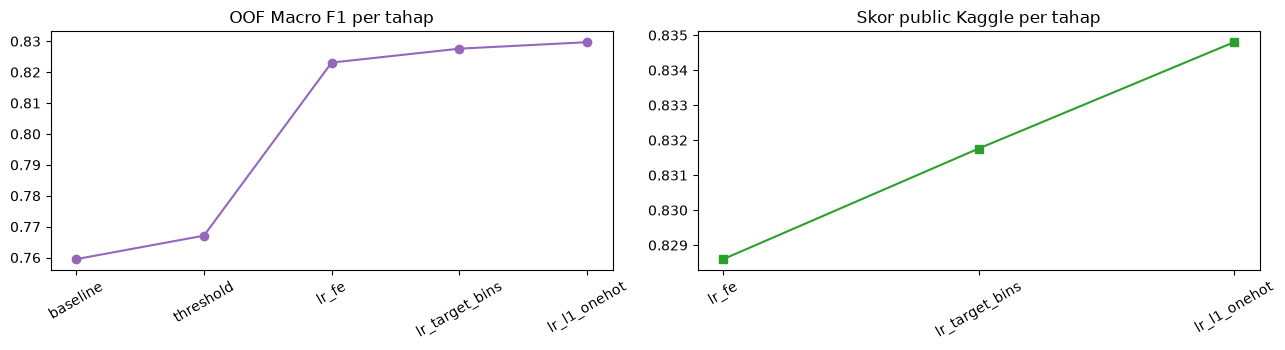

In [46]:
history = pd.DataFrame([
    ('baseline', 'data polos tanpa feature engineering, L2 dengan C = 1, threshold 0,5', 0.7595, None),
    ('threshold', 'ditambah tuning threshold (0,45)', 0.7671, None),
    ('lr_fe', 'bin kuantil, one-hot, interaksi 14 fitur, L2 dengan C = 0,03', 0.8231, 0.8286),
    ('lr_target_bins', 'bin berbasis target (16 bin), L2 dengan C = 0,01', 0.8276, 0.83176),
    ('lr_l1_onehot', 'one-hot num_adults dan num_children, L1 dengan C = 0,1', 0.8297, 0.8348),
], columns=['tahap', 'perubahan', 'OOF Macro F1', 'public Kaggle'])
display(history)

figure, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].plot(history['tahap'], history['OOF Macro F1'], marker='o', color='tab:purple')
axes[0].set_title('OOF Macro F1 per tahap')
axes[0].tick_params(axis='x', rotation=30)
published = history.dropna(subset=['public Kaggle'])
axes[1].plot(published['tahap'], published['public Kaggle'], marker='s', color='tab:green')
axes[1].set_title('Skor public Kaggle per tahap')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

#### Insights

> Skor naik terutama karena fitur, bukan karena hyperparameter.

- Lompatan terbesar (0,7671 ke 0,8231 OOF) datang dari feature engineering. Pada data polos, tuning `C` dan jenis regularisasi tidak menaikkan skor, jadi batas model ada pada bentuk fitur.
- Kenaikan setelah itu makin kecil (sekitar 0,002 sampai 0,005 per tahap), tanda perbaikan mulai jenuh.

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

Model from scratch dibandingkan dengan `sklearn.linear_model.LogisticRegression` pada **holdout** yang sama (`train_set` untuk training dan `val_set` untuk evaluasi, dengan matriks fitur yang sama persis). Fungsi objektif kedua model sama, sehingga `C` bisa dipakai langsung. `C = 0,1` dipakai untuk kedua pasangan.

| Pasangan | from scratch | scikit-learn |
| --- | --- | --- |
| L2 | FISTA | `lbfgs` |
| L1 | FISTA | `saga` (jalan jika `RUN_SK_L1 = True`) |

Metrik: nilai fungsi objektif di data latih (makin kecil makin dekat ke titik optimum), log-loss dan Macro F1 di `val_set` pada threshold model, selisih probabilitas antar model, dan waktu. Jika dijalankan di GPU, model L1 from scratch juga dilatih di CPU untuk memastikan hasilnya sama.

In [47]:
# mulai scikit-learn 1.8 jenis regularisasi diatur lewat l1_ratio, versi lama memakai parameter penalty
SK_NEW_API = tuple(int(v) for v in sklearn.__version__.split('.')[:2]) >= (1, 8)


# buat LogisticRegression scikit-learn dengan fungsi objektif yang sama dengan model from scratch
# lbfgs dipakai untuk L2 dan saga untuk L1 karena lbfgs tidak mendukung L1
def make_sklearn(penalty, C, tol=None, max_iter=10000):
    ratio = {'l2': 0.0, 'l1': 1.0}[penalty]
    solver = 'lbfgs' if penalty == 'l2' else 'saga'
    tol = tol if tol is not None else (1e-10 if solver == 'lbfgs' else 1e-6)
    common = dict(C=C, solver=solver, tol=tol, max_iter=max_iter)
    if SK_NEW_API:
        return SkLogisticRegression(l1_ratio=ratio, **common)
    return SkLogisticRegression(penalty=penalty, **common)


# nilai fungsi objektif yang sama dengan model from scratch, dihitung dari bobot model mana pun
def objective(coef, intercept, X, yv, C, penalty):
    z = np.asarray(X, dtype=float) @ coef + intercept
    data_term = float(np.mean(np.logaddexp(0.0, z) - yv * z))
    penalty_term = float(np.abs(coef).sum()) if penalty == 'l1' else 0.5 * float(coef @ coef)
    return data_term + penalty_term / (C * len(yv))


rows, probs = [], {}


# catat satu baris hasil perbandingan
def add_row(label, penalty, C, coef, intercept, proba, seconds, iterations):
    rows.append(dict(model=label, waktu_detik=round(seconds, 1), iterasi=iterations,
                     bobot_tidak_nol=int((coef != 0).sum()),
                     objektif_train=round(objective(coef, intercept, X_train, y_train, C, penalty), 6),
                     logloss_val=round(float(log_loss(y_val, proba)), 5),
                     macro_f1_val=round(macro_f1(y_val, (proba >= CFG.THRESHOLD).astype(int)), 4)))
    probs[label] = proba


# latih model scikit-learn dan peringatan konvergensi diredam karena jumlah iterasi dilaporkan di tabel
def fit_sklearn(label, penalty, C, **kwargs):
    sk = make_sklearn(penalty, C, **kwargs)
    start = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        sk.fit(X_train, y_train)
    seconds = time.perf_counter() - start
    add_row(label, penalty, C, sk.coef_[0], float(sk.intercept_[0]), sk.predict_proba(X_val)[:, 1], seconds, int(np.max(sk.n_iter_)))
    return sk


# model from scratch di holdout sudah dilatih di bagian Modeling dengan C yang sama
C_SK = CFG.LR_PARAMS['C']
dev = CFG.DEVICE.upper()
times = {r['regularisasi']: r['waktu_detik'] for r in holdout_rows}
for penalty, label in [('l2', 'L2'), ('l1', 'L1')]:
    m = holdout_models[penalty]
    add_row(f'scratch {label} ({dev})', penalty, C_SK, m.coef_, m.intercept_, m.predict_proba(X_val), times[label], m.n_iter_)

print('L2 scikit-learn (lbfgs) ...')
sk_l2 = fit_sklearn('sklearn L2 (lbfgs)', 'l2', C_SK, tol=1e-8, max_iter=3000)
if CFG.RUN_SK_L1:
    print('L1 scikit-learn (saga), bisa memakan beberapa menit ...')
    sk_l1 = fit_sklearn('sklearn L1 (saga)', 'l1', C_SK, tol=1e-4, max_iter=1000)
if CFG.RUN_CPU_CHECK and CFG.DEVICE != 'cpu':
    print('L1 from scratch di CPU ...')
    start = time.perf_counter()
    m_cpu = make_model(device='cpu', penalty='l1').fit(X_train, y_train)
    add_row('scratch L1 (CPU)', 'l1', C_SK, m_cpu.coef_, m_cpu.intercept_, m_cpu.predict_proba(X_val), time.perf_counter() - start, m_cpu.n_iter_)

# selisih probabilitas validasi terhadap model from scratch dengan regularisasi yang sama
ref = {'L1': f'scratch L1 ({dev})', 'L2': f'scratch L2 ({dev})'}
table = pd.DataFrame(rows)
table['selisih_proba_maks'] = [float(np.abs(probs[m] - probs[ref['L1' if 'L1' in m else 'L2']]).max()) for m in table['model']]
table['selisih_proba_rata2'] = [float(np.abs(probs[m] - probs[ref['L1' if 'L1' in m else 'L2']]).mean()) for m in table['model']]
display(table.set_index('model').round(6))

L2 scikit-learn (lbfgs) ...


,waktu_detik,iterasi,bobot_tidak_nol,objektif_train,logloss_val,macro_f1_val,selisih_proba_maks,selisih_proba_rata2
model,,,,,,,,
scratch L2 (CPU),195.9,1247,2032,0.289095,0.35877,0.8272,0.000000,0.000000
scratch L1 (CPU),70.9,329,989,0.322752,0.34128,0.8327,0.000000,0.000000
sklearn L2 (lbfgs),56.0,440,2032,0.289090,0.35864,0.8269,0.034598,0.000594


In [48]:
def objective_gap(a, b):
    ra = table.set_index('model')['objektif_train']
    return abs(float(ra[a] - ra[b])) if a in ra.index and b in ra.index else None


gap_l2 = objective_gap(f'scratch L2 ({dev})', 'sklearn L2 (lbfgs)')
gap_l1 = objective_gap(f'scratch L1 ({dev})', 'sklearn L1 (saga)')
lines = []
if gap_l2 is not None:
    lines.append(f'Pada L2, selisih nilai objektif antara from scratch dan scikit-learn (`lbfgs`) hanya {gap_l2:.2e}, '
                 f'dengan selisih probabilitas validasi paling besar {table.loc[table["model"] == "sklearn L2 (lbfgs)", "selisih_proba_maks"].iloc[0]:.4f}.')
if gap_l1 is not None:
    lines.append(f'Pada L1, selisih nilai objektif terhadap scikit-learn (`saga`) adalah {gap_l1:.2e}. '
                 f'Toleransi `saga` dibuat longgar (1e-4, maksimal 1000 epoch) supaya selesai dalam waktu wajar, jadi nilai objektif yang lebih kecil berarti lebih dekat ke titik optimum.')
else:
    lines.append('Pasangan L1 dengan `saga` dilewati (`RUN_SK_L1 = False`, bawaan di CPU). Ubah di Settings untuk menjalankannya.')
if CFG.RUN_CPU_CHECK and CFG.DEVICE != 'cpu':
    diff_pred = int(((probs[f'scratch L1 ({dev})'] >= CFG.THRESHOLD) != (probs['scratch L1 (CPU)'] >= CFG.THRESHOLD)).sum())
    lines.append(f'GPU dan CPU menghasilkan model yang sama sampai ketelitian numerik, dengan {diff_pred} prediksi berbeda dari {len(y_val)} baris validasi.')
display(Markdown('#### Insights\n\n> Model from scratch menghasilkan model yang setara dengan scikit-learn.\n\n' + '\n'.join('- ' + s for s in lines)))

#### Insights

> Model from scratch menghasilkan model yang setara dengan scikit-learn.

- Pada L2, selisih nilai objektif antara from scratch dan scikit-learn (`lbfgs`) hanya 5.00e-06, dengan selisih probabilitas validasi paling besar 0.0346.
- Pasangan L1 dengan `saga` dilewati (`RUN_SK_L1 = False`, bawaan di CPU). Ubah di Settings untuk menjalankannya.

### Perbandingan L1 dengan `saga` (dijalankan terpisah)

Pasangan L1 melawan `saga` dilewati pada run notebook ini (`RUN_SK_L1 = False` di CPU) karena `saga` sangat lambat pada matriks selebar ini. Perbandingannya dijalankan terpisah dengan konfigurasi dan holdout yang sama persis (`train_set` dan `val_set`, `C = 0,1`, threshold 0,45, `tol = 1e-4`, maksimal 1.000 epoch, scikit-learn 1.9.1, 2.032 kolom).

| | from scratch (FISTA) | scikit-learn (`saga`) |
|---|---|---|
| Waktu | 27,8 detik | 1.743,6 detik |
| Iterasi | 329 (konvergen) | 1.000 (batas maksimal) |
| Nilai objektif data latih | **0,322752** | 0,323381 |
| Log-loss validasi | **0,34128** | 0,34218 |
| Macro F1 validasi | 0,8327 | 0,8323 |
| Kolom dengan bobot tidak nol | 989 | 1.083 |

Selisih probabilitas validasi rata-rata 0,0056 (maksimum 0,2364). Pada threshold 0,45, 22 dari 5.462 baris validasi diprediksi berbeda.

#### Insights

> Hasil from scratch setara dengan scikit-learn pada metrik, dan nilai objektifnya sedikit lebih baik.

- Macro F1 validasi hampir sama (selisih 0,0004), dan hanya sekitar 0,5% prediksi yang berbeda.
- `saga` berhenti di batas 1.000 epoch tanpa konvergen, sehingga nilai objektifnya masih lebih tinggi (selisih 6,3e-04). FISTA konvergen dalam 329 iterasi.
- From scratch sekitar 63 kali lebih cepat pada data ini.
- Kolom dengan bobot tidak nol pada `saga` lebih banyak karena belum konvergen, dan hasilnya tidak identik dengan from scratch.


---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

Model final dilatih ulang pada seluruh `train_clean` (bukan hanya `train_set`), lalu disimpan bersama preprocessor dan threshold dalam satu file pickle lewat `save_model`, dan dimuat kembali dengan `load_model`. Memuat file pickle membutuhkan `src` ada di `sys.path`, karena class `LRPreprocessor` dan `LogisticRegression` harus bisa di-import.

In [49]:
prep_final = make_prep().fit(train_clean)
X_full = prep_final.transform(train_clean)
start = time.perf_counter()
model_final = make_model().fit(X_full, y_clean)
print(f'ukuran matriks final {X_full.shape} | iterasi {model_final.n_iter_} | konvergen {model_final.converged_} | '
      f'bobot tidak nol {int((model_final.coef_ != 0).sum())} | waktu training {time.perf_counter() - start:.1f} detik')

save_model({'preprocessor': prep_final, 'model': model_final, 'threshold': CFG.THRESHOLD, 'params': CFG.LR_PARAMS,
            'device': CFG.DEVICE, 'dtype': CFG.DTYPE}, CFG.MODEL_PATH)
loaded = load_model(CFG.MODEL_PATH)
print('model tersimpan di', CFG.MODEL_PATH.relative_to(ROOT), f'({CFG.MODEL_PATH.stat().st_size / 1024:.0f} KB)')

# model hasil load harus memberi prediksi yang sama dengan model di memori
same = np.allclose(model_final.predict_proba(X_full), loaded['model'].predict_proba(loaded['preprocessor'].transform(train_clean)))
print('prediksi model hasil load sama dengan model di memori:', bool(same))
assert same

ukuran matriks final (27309, 2097) | iterasi 371 | konvergen True | bobot tidak nol 1119 | waktu training 87.9 detik
model tersimpan di output\models\lr_l1_onehot.pkl (464 KB)


prediksi model hasil load sama dengan model di memori: True


#### Insights

> Preprocessor, model, dan threshold disimpan dalam satu file.

- Dengan satu file, pasangan yang benar selalu dipakai bersama, sehingga tidak ada risiko threshold atau statistik preprocessing salah pasangan.
- Pemeriksaan `np.allclose` memastikan proses save dan load tidak mengubah prediksi. Prediksi tidak membutuhkan GPU karena `coef_` dan `intercept_` sudah disalin ke CPU setelah training.

---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [50]:
X_test_final = loaded['preprocessor'].transform(test_df)
submission = pd.DataFrame({CFG.ID_COLUMN: test_df[CFG.ID_COLUMN],
                           CFG.TARGET: loaded['model'].predict(X_test_final, threshold=loaded['threshold'])})
assert len(submission) == len(sample) and set(submission[CFG.ID_COLUMN]) == set(sample[CFG.ID_COLUMN])
assert list(submission.columns) == list(sample.columns)
CFG.SUB_PATH.parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(CFG.SUB_PATH, index=False)

print('rasio batal prediksi', submission[CFG.TARGET].mean().round(4), f'(rasio batal train {y_clean.mean():.4f})')
print('md5 submission:', hashlib.md5(open(CFG.SUB_PATH, 'rb').read()).hexdigest())

# perbandingan dengan file yang sudah diunggah ke Kaggle sebelumnya
if CFG.REF_SUB_PATH.exists():
    ref_sub = pd.read_csv(CFG.REF_SUB_PATH, dtype={CFG.ID_COLUMN: str})
    same_ids = bool((ref_sub[CFG.ID_COLUMN].values == submission[CFG.ID_COLUMN].values).all())
    diff = int((ref_sub[CFG.TARGET].values != submission[CFG.TARGET].values).sum())
    print(f'dibanding {CFG.REF_SUB_PATH.name}: id sama {same_ids}, prediksi berbeda {diff} dari {len(submission)} baris')
else:
    print('file submission acuan tidak ditemukan, bagian perbandingan dilewati')
submission.head()

rasio batal prediksi 0.3137 (rasio batal train 0.3275)
md5 submission: 3ca63f448ea95a5288467053f3a61cf0
dibanding submission_lr_tuning_l1_onehot.csv: id sama True, prediksi berbeda 0 dari 6844 baris


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


#### Insights

> File ini sama dengan submission `submission_lr_tuning_l1_onehot.csv` yang sudah diunggah ke Kaggle (public score **0,83480**).

- Jumlah prediksi yang berbeda terhadap file acuan harus 0. Itu membuktikan notebook ini reproducible, yaitu menghasilkan nilai akhir yang sama dengan submisi Kaggle.
- Perbedaan beberapa baris saja bisa muncul dari perbedaan versi library, dan bisa dicek lewat versi yang dicetak di bagian Import Libraries.
- Submission ini tidak dipakai sebagai submission utama kelompok, karena model lain mendapat skor lebih tinggi.

---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

Analisis memakai prediksi OOF (`oof`) dan threshold `CFG.THRESHOLD`. Setiap baris diprediksi oleh model yang tidak pernah melihat baris itu.

## Confusion Matrix

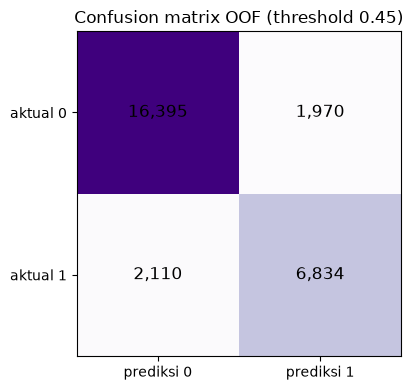

,presisi,recall,F1
tidak batal (0),0.8860,0.8927,0.8893
batal (1),0.7762,0.7641,0.7701


In [51]:
(tn, fp), (fn, tp) = confusion_matrix(y_clean, pred_oof)
f1_0, f1_1 = f1_per_class(y_clean, pred_oof)
precision_1, recall_1 = tp / (tp + fp), tp / (tp + fn)
precision_0, recall_0 = tn / (tn + fn), tn / (tn + fp)

figure, ax = plt.subplots(figsize=(4.5, 4))
cm = np.array([[tn, fp], [fn, tp]])
ax.imshow(cm, cmap='Purples')
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontsize=12)
ax.set_xticks([0, 1], ['prediksi 0', 'prediksi 1'])
ax.set_yticks([0, 1], ['aktual 0', 'aktual 1'])
ax.set_title(f'Confusion matrix OOF (threshold {CFG.THRESHOLD})')
plt.tight_layout()
plt.show()

display(pd.DataFrame({'presisi': [precision_0, precision_1], 'recall': [recall_0, recall_1], 'F1': [f1_0, f1_1]},
                     index=['tidak batal (0)', 'batal (1)']).round(4))

In [52]:
display(Markdown(
    f'#### Insights\n\n'
    f'> Dari {int(y_clean.sum()):,} pemesanan yang benar-benar batal, model menangkap {tp:,} (recall {recall_1:.3f}) dan melewatkan {fn:,}.\n\n'
    f'- Dari {tp + fp:,} pemesanan yang diprediksi batal, {tp:,} benar (presisi {precision_1:.3f}). Ada {fp:,} False Positive dan {fn:,} False Negative.\n'
    f'- False Positive membuat kamar dijual ulang padahal tamu datang (risiko overbooked), sehingga bobotnya berbeda dan dibahas di bagian Bonus cost-sensitive.'))

#### Insights

> Dari 8,944 pemesanan yang benar-benar batal, model menangkap 6,834 (recall 0.764) dan melewatkan 2,110.

- Dari 8,804 pemesanan yang diprediksi batal, 6,834 benar (presisi 0.776). Ada 1,970 False Positive dan 2,110 False Negative.
- False Positive membuat kamar dijual ulang padahal tamu datang (risiko overbooked), sehingga bobotnya berbeda dan dibahas di bagian Bonus cost-sensitive.

## Kesalahan per Kelompok

In [53]:
def error_by(values, name):
    frame = pd.DataFrame({name: values, 'error': pred_oof != y_clean})
    return frame.groupby(name, observed=True, dropna=False)['error'].agg(['mean', 'size']).round(3)

In [54]:
error_by(pd.qcut(train_clean['days_before_arrival'], 5, duplicates='drop'), 'days_before_arrival')

,mean,size
days_before_arrival,,
"(-0.001, 11.0]",0.087,5286
"(11.0, 39.0]",0.146,5332
"(39.0, 80.0]",0.163,5186
"(80.0, 151.0]",0.227,5180
"(151.0, 448.0]",0.106,5205
NaN,0.242,1120


In [55]:
error_by(train_clean['special_requests'], 'special_requests')

,mean,size
special_requests,,
0.0,0.164,12678
1.0,0.157,8323
2.0,0.083,3246
3.0,0.000,496
4.0,0.000,60
5.0,0.000,7
NaN,0.169,2499


In [56]:
error_by(train_clean['booking_channel'], 'booking_channel')

,mean,size
booking_channel,,
Airline,0.205,88
Complimentary,0.003,300
Corporate,0.099,1512
Offline Agent,0.091,7902
Online Travel Agent,0.182,17507


In [57]:
error_by(train_clean['arrival_year'], 'arrival_year')

,mean,size
arrival_year,,
2023,0.094,4900
2024,0.161,22409


In [58]:
segments = pd.concat({'lead time': error_by(pd.qcut(train_clean['days_before_arrival'], 5, duplicates='drop').astype(str), 'segmen'),
                      'special_requests': error_by(train_clean['special_requests'].astype(str), 'segmen'),
                      'booking_channel': error_by(train_clean['booking_channel'].astype(str), 'segmen'),
                      'arrival_year': error_by(train_clean['arrival_year'].astype(str), 'segmen')}, names=['fitur', 'segmen'])
segments = segments[segments['size'] >= 200].sort_values('mean', ascending=False)
overall_error = float((pred_oof != y_clean).mean())
top_f, top_s = segments.index[0]
low_f, low_s = segments.index[-1]
display(Markdown(
    f'#### Insights\n\n'
    f'> Tingkat kesalahan keseluruhan {overall_error:.3f}, dan segmen tersulit adalah **{top_f} = {top_s}** ({segments.iloc[0]["mean"]:.3f}, {int(segments.iloc[0]["size"]):,} baris).\n\n'
    f'- Segmen paling mudah adalah **{low_f} = {low_s}** ({segments.iloc[-1]["mean"]:.3f}).\n'
    f'- Segmen dengan kurang dari 200 baris diabaikan supaya angkanya tidak menyesatkan.'))

#### Insights

> Tingkat kesalahan keseluruhan 0.149, dan segmen tersulit adalah **lead time = nan** (0.242, 1,120 baris).

- Segmen paling mudah adalah **special_requests = 3.0** (0.000).
- Segmen dengan kurang dari 200 baris diabaikan supaya angkanya tidak menyesatkan.

## Kalibrasi Probabilitas

Probabilitas OOF dikelompokkan per 0,1 lalu dibandingkan dengan rasio batal aktual. Model yang terkalibrasi punya titik di sekitar garis diagonal.

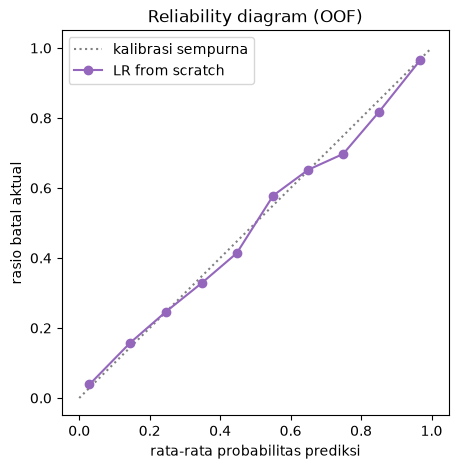

,rata_proba,rasio_batal,jumlah
bin,,,
0,0.029,0.039,11293
1,0.145,0.158,3250
2,0.246,0.247,2020
3,0.348,0.328,1355
4,0.447,0.414,1097
5,0.551,0.578,1136
6,0.650,0.652,1308
7,0.749,0.697,1322
8,0.851,0.817,1390


#### Insights

> Selisih terbesar antara rata-rata probabilitas dan rasio batal aktual pada satu kelompok adalah 0.052, rata-ratanya 0.019.

- Probabilitas yang cukup terkalibrasi penting karena threshold cost-sensitive di bagian Bonus diturunkan dari teori yang mengandaikan probabilitas yang bisa dipercaya.

In [59]:
edges_cal = np.linspace(0, 1, 11)
bin_cal = np.clip(np.digitize(oof, edges_cal) - 1, 0, 9)
calib = (pd.DataFrame({'proba': oof, 'aktual': y_clean, 'bin': bin_cal})
         .groupby('bin').agg(rata_proba=('proba', 'mean'), rasio_batal=('aktual', 'mean'), jumlah=('aktual', 'size')))

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], linestyle=':', color='gray', label='kalibrasi sempurna')
plt.plot(calib['rata_proba'], calib['rasio_batal'], marker='o', color='tab:purple', label='LR from scratch')
plt.xlabel('rata-rata probabilitas prediksi')
plt.ylabel('rasio batal aktual')
plt.legend()
plt.title('Reliability diagram (OOF)')
plt.show()
display(calib.round(3))

calib_gap = (calib['rata_proba'] - calib['rasio_batal']).abs()
display(Markdown(
    f'#### Insights\n\n'
    f'> Selisih terbesar antara rata-rata probabilitas dan rasio batal aktual pada satu kelompok adalah {calib_gap.max():.3f}, rata-ratanya {calib_gap.mean():.3f}.\n\n'
    f'- Probabilitas yang cukup terkalibrasi penting karena threshold cost-sensitive di bagian Bonus diturunkan dari teori yang mengandaikan probabilitas yang bisa dipercaya.'))

## Fitur yang Paling Berpengaruh

Fitur sudah distandardisasi, sehingga besar bobot bisa dibandingkan antar kolom. Bobot positif menaikkan peluang batal dan bobot negatif menurunkannya.

,kolom,dipakai,persen_dipakai
interaksi,1941,1035,53.3
bin,88,49,55.7
dasar dan one-hot,68,35,51.5


kolom dipakai: 1119 dari 2097 (53.4%)


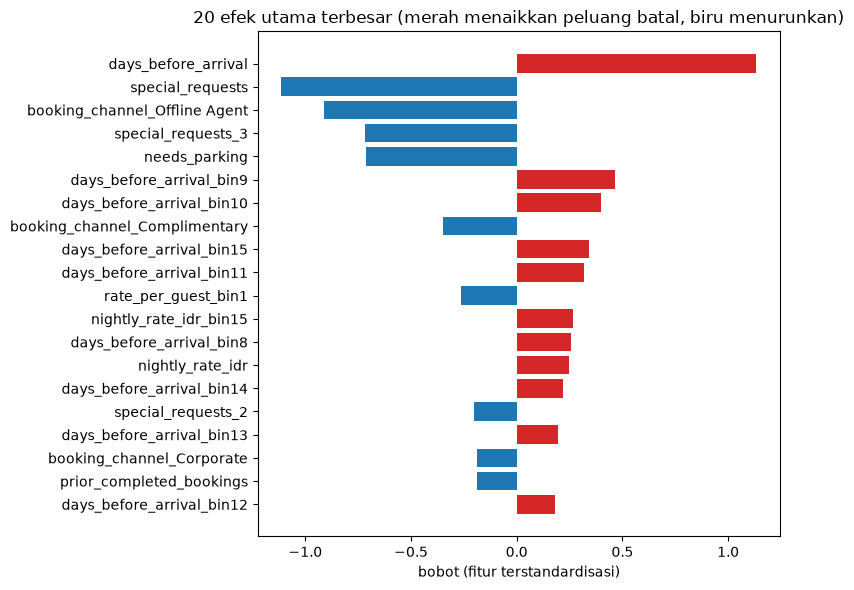

In [60]:
coef = pd.Series(model_final.coef_, index=model_final.feature_names_)
nonzero = coef[coef != 0]
kinds = pd.Series([column_group(c) for c in coef.index], index=coef.index)
usage = pd.DataFrame({'kolom': kinds.value_counts(), 'dipakai': kinds[nonzero.index].value_counts()}).fillna(0).astype(int)
usage['persen_dipakai'] = (usage['dipakai'] / usage['kolom'] * 100).round(1)
display(usage)
print(f'kolom dipakai: {len(nonzero)} dari {len(coef)} ({len(nonzero) / len(coef):.1%})')

main_effects = nonzero[[column_group(c) in ('dasar dan one-hot', 'bin') for c in nonzero.index]]
top_main = main_effects.reindex(main_effects.abs().sort_values(ascending=False).index).head(20)
figure, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_main.index[::-1], top_main.values[::-1], color=['tab:red' if v > 0 else 'tab:blue' for v in top_main.values[::-1]])
ax.set_xlabel('bobot (fitur terstandardisasi)')
ax.set_title('20 efek utama terbesar (merah menaikkan peluang batal, biru menurunkan)')
plt.tight_layout()
plt.show()

In [61]:
pos_names = ', '.join(f'`{c}`' for c in main_effects.sort_values(ascending=False).head(4).index)
neg_names = ', '.join(f'`{c}`' for c in main_effects.sort_values().head(4).index)
display(Markdown(
    f'#### Insights\n\n'
    f'> Model memakai {len(nonzero)} dari {len(coef)} kolom ({len(nonzero) / len(coef):.1%}).\n\n'
    f'- Efek utama yang paling menaikkan peluang batal: {pos_names}.\n'
    f'- Efek utama yang paling menurunkan peluang batal: {neg_names}.\n'
    f'- Bobot kolom interaksi sulit dibaca satu per satu, sehingga efek utama di atas lebih mudah dijelaskan ke pihak hotel.'))

#### Insights

> Model memakai 1119 dari 2097 kolom (53.4%).

- Efek utama yang paling menaikkan peluang batal: `days_before_arrival`, `days_before_arrival_bin9`, `days_before_arrival_bin10`, `days_before_arrival_bin15`.
- Efek utama yang paling menurunkan peluang batal: `special_requests`, `booking_channel_Offline Agent`, `special_requests_3`, `needs_parking`.
- Bobot kolom interaksi sulit dibaca satu per satu, sehingga efek utama di atas lebih mudah dijelaskan ke pihak hotel.

---

# Bonus <a name="12"></a>

---

Bagian ini berisi kode untuk bonus Logistic Regression: cost-sensitive classification, optimasi model dengan FISTA, dan video kontur log-loss. Penjelasan metodenya ada di bagian Referensi.

## Cost-Sensitive Classification

Pada task ini kelas positif adalah pemesanan yang batal.

- **False Positive (FP)**: pemesanan yang sebenarnya datang diprediksi batal. Hotel menjual ulang kamarnya, sehingga saat tamu datang kamar sudah penuh (overbooked).
- **False Negative (FN)**: pemesanan yang batal tidak terdeteksi, sehingga kamar kosong dan pendapatan hilang.

Dengan asumsi FP dua kali lebih mahal daripada FN:

| | Prediksi tidak batal | Prediksi batal |
| --- | --- | --- |
| **Aktual tidak batal** | benar, biaya 0 | **FP, biaya 2** |
| **Aktual batal** | **FN, biaya 1** | benar, biaya 0 |

Metrik yang diminimalkan adalah **biaya total = 2 x FP + FN**.

**Threshold optimal.** Jika model memberi probabilitas batal $p$ yang terkalibrasi, biaya harapan prediksi batal adalah $(1-p)\,c_{FP}$ dan biaya harapan prediksi tidak batal adalah $p\,c_{FN}$. Prediksi batal lebih murah jika

$$p > \frac{c_{FP}}{c_{FP} + c_{FN}} = \frac{2}{2 + 1} = \frac{2}{3}$$

Jadi threshold naik dari sekitar 0,5 menjadi sekitar 0,67. Model menjadi lebih hati-hati menyatakan sebuah pemesanan batal.

**Pembobotan kelas.** Cara kedua adalah memasukkan biaya ke training. Sampel kelas 0 (sumber FP) diberi bobot 2 pada log-loss, sehingga threshold teoretisnya kembali ke 0,5. Kedua cara ini dibahas oleh Elkan [4]. Keduanya dibandingkan dengan threshold yang dipilih langsung dari data (biaya OOF terkecil).

In [62]:
COST_FP, COST_FN = CFG.COST_FP, CFG.COST_FN
THR_GRID = np.round(np.arange(0.05, 0.951, 0.005), 3)


# biaya total dengan FP lebih mahal dari FN
def total_cost(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix(y_true, y_pred)
    return COST_FP * fp + COST_FN * fn


# threshold dengan biaya OOF terkecil
def min_cost_threshold(proba):
    costs = np.array([total_cost(y_clean, (proba >= t).astype(int)) for t in THR_GRID])
    return float(THR_GRID[int(np.argmin(costs))])


# ringkasan satu strategi: FP, FN, biaya, Macro F1, serta presisi dan recall kelas batal
def evaluate(label, proba, threshold):
    pred = (proba >= threshold).astype(int)
    (tn, fp), (fn, tp) = confusion_matrix(y_clean, pred)
    return dict(strategi=label, threshold=round(threshold, 3), FP=fp, FN=fn,
                biaya_total=COST_FP * fp + COST_FN * fn,
                biaya_per_pemesanan=round((COST_FP * fp + COST_FN * fn) / len(y_clean), 4),
                macro_f1=round(macro_f1(y_clean, pred), 4),
                presisi_batal=round(tp / max(tp + fp, 1), 4), recall_batal=round(tp / max(tp + fn, 1), 4))


# model dengan bobot kelas 2:1 dilatih pada fitur yang sama, jumlah fold dan preprocessing sama dengan model biasa
make_model_weighted = lambda: make_model(class_weight={0: COST_FP, 1: COST_FN})
start = time.perf_counter()
oof_w = cross_val_proba(make_model_weighted, make_prep, train_clean, y_clean, folds)
print(f'waktu validasi model berbobot {time.perf_counter() - start:.0f} detik')
print('rata-rata probabilitas tanpa bobot', round(oof.mean(), 4), '| dengan bobot', round(oof_w.mean(), 4))

thr_f1 = CFG.THRESHOLD
thr_cost = min_cost_threshold(oof)
thr_cost_w = min_cost_threshold(oof_w)

waktu validasi model berbobot 814 detik
rata-rata probabilitas tanpa bobot 0.3275 | dengan bobot 0.266


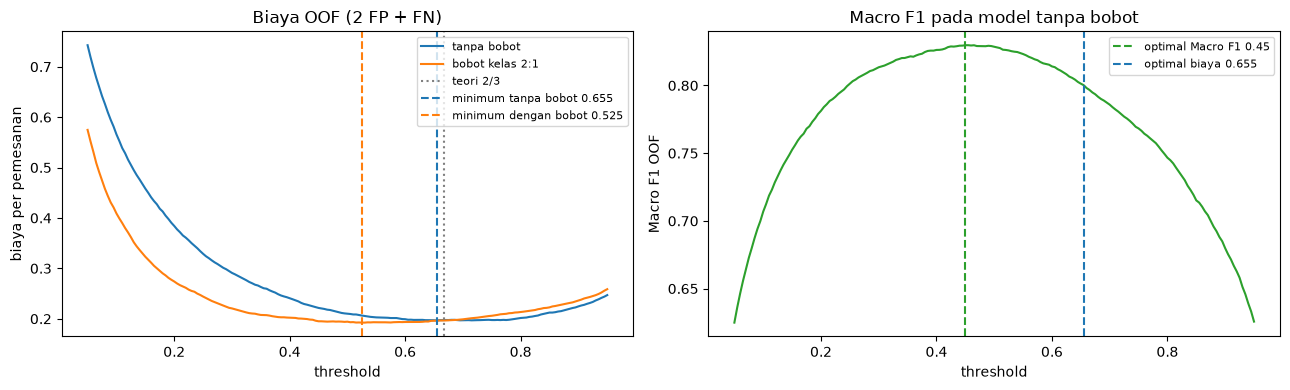

In [63]:
cost_plain = [total_cost(y_clean, (oof >= t).astype(int)) / len(y_clean) for t in THR_GRID]
cost_w = [total_cost(y_clean, (oof_w >= t).astype(int)) / len(y_clean) for t in THR_GRID]
f1_plain = [macro_f1(y_clean, (oof >= t).astype(int)) for t in THR_GRID]

figure, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(THR_GRID, cost_plain, label='tanpa bobot')
axes[0].plot(THR_GRID, cost_w, label='bobot kelas 2:1')
axes[0].axvline(2 / 3, color='gray', linestyle=':', label='teori 2/3')
axes[0].axvline(thr_cost, color='tab:blue', linestyle='--', label=f'minimum tanpa bobot {thr_cost}')
axes[0].axvline(thr_cost_w, color='tab:orange', linestyle='--', label=f'minimum dengan bobot {thr_cost_w}')
axes[0].set_xlabel('threshold')
axes[0].set_ylabel('biaya per pemesanan')
axes[0].set_title('Biaya OOF (2 FP + FN)')
axes[0].legend(fontsize=8)
axes[1].plot(THR_GRID, f1_plain, color='tab:green')
axes[1].axvline(thr_f1, color='tab:green', linestyle='--', label=f'optimal Macro F1 {thr_f1}')
axes[1].axvline(thr_cost, color='tab:blue', linestyle='--', label=f'optimal biaya {thr_cost}')
axes[1].set_xlabel('threshold')
axes[1].set_ylabel('Macro F1 OOF')
axes[1].set_title('Macro F1 pada model tanpa bobot')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [64]:
strategies = [
    ('tanpa model: semua tidak batal',          np.zeros(len(y_clean)), 0.5),
    ('tanpa penanganan: threshold Macro F1',    oof, thr_f1),
    ('threshold default 0,5',                   oof, 0.5),
    ('threshold teoretis 2/3',                  oof, 2 / 3),
    ('threshold empiris biaya minimum',         oof, thr_cost),
    ('bobot kelas 2:1, threshold 0,5',          oof_w, 0.5),
    ('bobot kelas 2:1, threshold empiris',      oof_w, thr_cost_w),
]
cost_table = pd.DataFrame([evaluate(label, p, t) for label, p, t in strategies])
base_cost = cost_table.loc[1, 'biaya_total']
cost_table['hemat_vs_tanpa_penanganan'] = ((base_cost - cost_table['biaya_total']) / base_cost * 100).round(1).astype(str) + '%'
display(cost_table)

models_only = cost_table.iloc[1:]
best_cost = models_only.loc[models_only['biaya_total'].idxmin()]
base = cost_table.iloc[1]
display(Markdown(
    f'#### Insights\n\n'
    f'> Strategi dengan biaya terkecil adalah **{best_cost["strategi"]}** (threshold {best_cost["threshold"]}), biaya total {int(best_cost["biaya_total"]):,} '
    f'({best_cost["hemat_vs_tanpa_penanganan"]} lebih hemat).\n\n'
    f'- Tanpa penanganan (threshold Macro F1 {thr_f1}), biaya total {int(base["biaya_total"]):,} dengan {int(base["FP"]):,} FP dan {int(base["FN"]):,} FN.\n'
    f'- Pada strategi terbaik, FP turun menjadi {int(best_cost["FP"]):,} dan FN naik menjadi {int(best_cost["FN"]):,}. Model sengaja membiarkan lebih banyak batal yang tidak terdeteksi demi menghindari overbooked.\n'
    f'- Harganya adalah Macro F1, dari {base["macro_f1"]:.4f} menjadi {best_cost["macro_f1"]:.4f}. Ini trade-off yang diharapkan karena Macro F1 memperlakukan FP dan FN sama.\n'
    f'- Threshold teoretis 2/3 memberi biaya {int(cost_table.loc[3, "biaya_total"]):,} dan threshold empiris dari data memberi {int(cost_table.loc[4, "biaya_total"]):,}. '
    f'Keduanya berdekatan jika probabilitas model cukup terkalibrasi.\n'
    f'- Pembobotan kelas 2:1 (threshold 0,5) memberi biaya {int(cost_table.loc[5, "biaya_total"]):,}, mirip dengan menaikkan threshold, karena kedua cara memindahkan batas keputusan ke arah yang sama.'))

,strategi,threshold,FP,FN,biaya_total,biaya_per_pemesanan,macro_f1,presisi_batal,recall_batal,hemat_vs_tanpa_penanganan
0,tanpa model: semua tidak batal,0.500,0,8944,8944,0.3275,0.4021,0.0000,0.0000,-47.8%
1,tanpa penanganan: threshold Macro F1,0.450,1970,2110,6050,0.2215,0.8297,0.7762,0.7641,0.0%
2,"threshold default 0,5",0.500,1697,2347,5741,0.2102,0.8286,0.7954,0.7376,5.1%
3,threshold teoretis 2/3,0.667,916,3565,5397,0.1976,0.7961,0.8545,0.6014,10.8%
4,threshold empiris biaya minimum,0.655,957,3459,5373,0.1967,0.8002,0.8514,0.6133,11.2%
5,"bobot kelas 2:1, threshold 0,5",0.500,925,3455,5305,0.1943,0.8016,0.8558,0.6137,12.3%
6,"bobot kelas 2:1, threshold empiris",0.525,816,3622,5254,0.1924,0.7967,0.8671,0.5950,13.2%


#### Insights

> Strategi dengan biaya terkecil adalah **bobot kelas 2:1, threshold empiris** (threshold 0.525), biaya total 5,254 (13.2% lebih hemat).

- Tanpa penanganan (threshold Macro F1 0.45), biaya total 6,050 dengan 1,970 FP dan 2,110 FN.
- Pada strategi terbaik, FP turun menjadi 816 dan FN naik menjadi 3,622. Model sengaja membiarkan lebih banyak batal yang tidak terdeteksi demi menghindari overbooked.
- Harganya adalah Macro F1, dari 0.8297 menjadi 0.7967. Ini trade-off yang diharapkan karena Macro F1 memperlakukan FP dan FN sama.
- Threshold teoretis 2/3 memberi biaya 5,397 dan threshold empiris dari data memberi 5,373. Keduanya berdekatan jika probabilitas model cukup terkalibrasi.
- Pembobotan kelas 2:1 (threshold 0,5) memberi biaya 5,305, mirip dengan menaikkan threshold, karena kedua cara memindahkan batas keputusan ke arah yang sama.

**Penanganan yang berubah.** Keputusan tidak lagi dinilai dengan Macro F1 saja, tetapi dengan biaya total $2\,FP + FN$. Threshold naik dari threshold Macro F1 ke kisaran 0,6 sampai 0,7 menurut teori, dan nilai persisnya dari data ada pada tabel di atas. Alternatifnya memberi bobot 2 pada kelas 0 saat training. Skor kompetisi tetap Macro F1, sehingga submission Kaggle memakai threshold Macro F1. Strategi cost-sensitive adalah rekomendasi untuk operasional hotel, bukan untuk leaderboard.

## Optimasi Model dengan FISTA

Gradient descent biasa (diajarkan di kelas) menghitung gradien di titik parameter sekarang. FISTA menghitung gradien di titik yang sudah digeser searah gerakan sebelumnya (momentum Nesterov), ditambah adaptive restart dan langkah $1/L$. Kedua solver meminimalkan fungsi objektif yang sama, jadi model akhirnya sama dan FISTA hanya membuat training lebih cepat. Perbandingan di bawah memakai fitur dan konfigurasi notebook ini pada `train_set`. Bagian gradient descent biasa lambat, jadi hanya berjalan jika `RUN_OPTIMIZER_GD = True`.

,solver,iterasi,konvergen,waktu_detik,objektif,bobot_tidak_nol
0,FISTA,329,True,40.0,0.322752,989


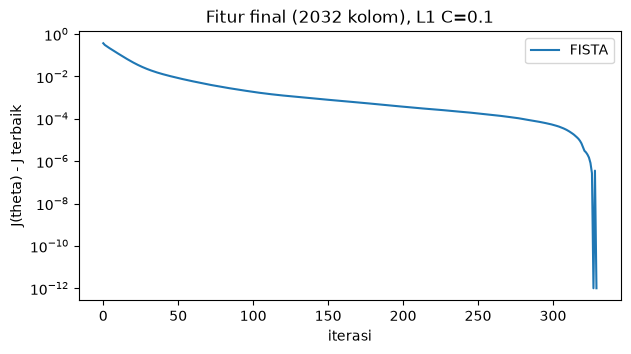

In [65]:
# latih satu konfigurasi pada train_set dan catat iterasi, waktu, serta nilai objektif akhir
def benchmark(label, **params):
    start = time.perf_counter()
    m = make_model(**params).fit(X_train, y_train)
    return m, dict(solver=label, iterasi=m.n_iter_, konvergen=bool(m.converged_),
                   waktu_detik=round(time.perf_counter() - start, 2), objektif=round(m.loss_history_[-1], 7),
                   bobot_tidak_nol=int((m.coef_ != 0).sum()))


# gambar selisih objektif terhadap nilai terbaik di setiap iterasi dalam skala log
def plot_gap(models, title):
    best_obj = min(m.loss_history_[-1] for m in models.values())
    plt.figure(figsize=(7, 3.5))
    for label, m in models.items():
        gap = np.maximum(np.array(m.loss_history_) - best_obj, 1e-12)
        plt.semilogy(gap, label=label)
    plt.xlabel('iterasi')
    plt.ylabel('J(theta) - J terbaik')
    plt.title(title)
    plt.legend()
    plt.show()


opt_models, opt_rows = {}, []
m_fista, r_fista = benchmark('FISTA', solver='fista')
opt_models['FISTA'] = m_fista
opt_rows.append(r_fista)
if CFG.RUN_OPTIMIZER_GD:
    m_gd, r_gd = benchmark('GD', solver='gd', max_iter=3000)
    opt_models['GD'] = m_gd
    opt_rows.append(r_gd)
display(pd.DataFrame(opt_rows))
plot_gap(opt_models, f'Fitur final ({X_train.shape[1]} kolom), {CFG.LR_PARAMS["penalty"].upper()} C={CFG.LR_PARAMS["C"]}')

In [66]:
if 'GD' in opt_models:
    ratio_iter = r_gd['iterasi'] / r_fista['iterasi']
    ratio_time = r_gd['waktu_detik'] / max(r_fista['waktu_detik'], 1e-9)
    gd_state = 'konvergen' if r_gd['konvergen'] else f'belum memenuhi toleransi setelah {r_gd["iterasi"]:,} iterasi'
    gap = r_gd['objektif'] - r_fista['objektif']
    p_gap = float(np.abs(opt_models['GD'].predict_proba(X_val) - m_fista.predict_proba(X_val)).max())
    display(Markdown(
        f'#### Insights\n\n'
        f'> FISTA konvergen dalam {r_fista["iterasi"]:,} iterasi ({r_fista["waktu_detik"]} detik), sedangkan gradient descent biasa {gd_state} ({r_gd["waktu_detik"]} detik).\n\n'
        f'- Gradient descent memakai {ratio_iter:.1f} kali lebih banyak iterasi dan {ratio_time:.1f} kali lebih banyak waktu.\n'
        f'- Nilai objektif GD masih {gap:+.2e} terhadap FISTA, dan probabilitas validasi keduanya berbeda paling besar {p_gap:.4f}.\n'
        f'- Pada grafik, galat FISTA turun beberapa orde lebih cepat, dan lekukan pada kurvanya adalah titik ketika adaptive restart me-reset momentum.'))
else:
    display(Markdown('#### Insights\n\n> Bagian gradient descent dilewati (`RUN_OPTIMIZER_GD = False`, bawaan di CPU), sehingga hanya FISTA yang ditampilkan.'))

#### Insights

> Bagian gradient descent dilewati (`RUN_OPTIMIZER_GD = False`, bawaan di CPU), sehingga hanya FISTA yang ditampilkan.

## Video Kontur Log-Loss dan Lintasan Parameter

Agar fungsi loss bisa digambar dalam dua dimensi, model dibuat hanya dengan dua parameter:

$$P(\text{batal}) = \sigma(\theta_0 + \theta_1 x)$$

dengan $x$ adalah `special_requests` yang sudah distandardisasi, yaitu sinyal tunggal terkuat pada data. Regularisasi tidak dipakai agar yang digambar murni log-loss:

$$J(\theta_0, \theta_1) = \frac{1}{m} \sum_i \Big[\log\big(1 + e^{z_i}\big) - y_i z_i\Big], \quad z_i = \theta_0 + \theta_1 x_i$$

Tiga lintasan dibandingkan dari titik awal yang sama (0, 0):

| Lintasan | Keterangan |
| --- | --- |
| GD, learning rate 0,5 | gradient descent seperti di kelas, langkah kecil dan stabil |
| GD, learning rate 7 | langkah terlalu besar, parameter melompat ke sisi lain lembah |
| FISTA | gradient descent dengan momentum Nesterov dan langkah 1/L |

Training dua parameter ini berjalan di CPU karena terlalu kecil untuk GPU. Gambar dan video disimpan di `output/figures/`.

In [67]:
prep_c = LRPreprocessor(feature_engineering=False, log_skewed=False, cyclic=False).fit(train_clean)
x_contour = prep_c.transform(train_clean)[[CFG.CONTOUR_FEATURE]]

common = dict(penalty=None, tol=1e-6, max_iter=5000, record_params=True)
runs = {
    'GD lr=0,5': LogisticRegression(solver='gd', learning_rate=0.5, **common).fit(x_contour, y_clean),
    'GD lr=7': LogisticRegression(solver='gd', learning_rate=7.0, **common).fit(x_contour, y_clean),
    'FISTA (lr=1/L)': LogisticRegression(solver='fista', **common).fit(x_contour, y_clean),
}
for label, m in runs.items():
    print(f'{label:16s} iterasi {m.n_iter_:4d}  learning rate {m.learning_rate_:.2f}  '
          f'theta0 {m.intercept_:+.4f}  theta1 {m.coef_[0]:+.4f}  loss {m.loss_history_[-1]:.5f}')

final_params = np.array([[m.intercept_, m.coef_[0]] for m in runs.values()])
loss_final = np.array([m.loss_history_[-1] for m in runs.values()])
display(Markdown(
    f'#### Insights\n\n'
    f'> Ketiga lintasan berakhir di titik yang sama (selisih parameter terbesar {np.abs(final_params - final_params[0]).max():.1e}, selisih log-loss {loss_final.max() - loss_final.min():.1e}).\n\n'
    f'- Ini sesuai sifat log-loss yang cembung: hanya ada satu titik minimum, dan learning rate hanya memengaruhi jalan menuju titik itu.\n'
    f'- Jumlah iterasi masing-masing: ' + ', '.join(f'{k} {m.n_iter_}' for k, m in runs.items()) + '.'))

GD lr=0,5        iterasi  174  learning rate 0.50  theta0 -0.8026  theta1 -0.6625  loss 0.59674
GD lr=7          iterasi   32  learning rate 7.00  theta0 -0.8026  theta1 -0.6625  loss 0.59674
FISTA (lr=1/L)   iterasi   16  learning rate 4.00  theta0 -0.8026  theta1 -0.6625  loss 0.59674


#### Insights

> Ketiga lintasan berakhir di titik yang sama (selisih parameter terbesar 1.6e-05, selisih log-loss 1.8e-11).

- Ini sesuai sifat log-loss yang cembung: hanya ada satu titik minimum, dan learning rate hanya memengaruhi jalan menuju titik itu.
- Jumlah iterasi masing-masing: GD lr=0,5 174, GD lr=7 32, FISTA (lr=1/L) 16.

loss di titik optimum dari grid 0.59674 | dari model 0.59674


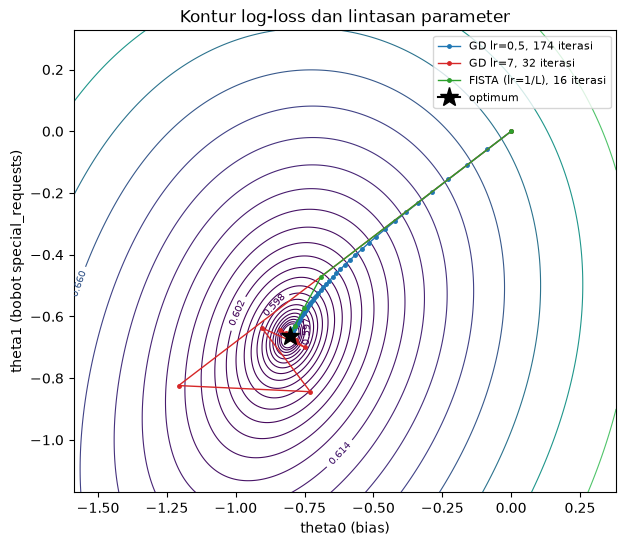

gambar tersimpan di output\figures\lr_l1_onehot_contour.png


In [68]:
xv = x_contour[CFG.CONTOUR_FEATURE].to_numpy()
values, inverse = np.unique(xv, return_inverse=True)
n_pos = np.bincount(inverse, weights=y_clean, minlength=len(values))
n_neg = np.bincount(inverse, minlength=len(values)) - n_pos


# log-loss rata-rata untuk setiap pasangan (theta0, theta1) pada grid, data diringkas per nilai unik
def loss_surface(T0, T1):
    Z = T0[..., None] + T1[..., None] * values
    softplus = np.logaddexp(0.0, Z)
    return (n_pos * (softplus - Z) + n_neg * softplus).sum(-1) / len(y_clean)


paths = np.vstack([m.param_history_ for m in runs.values()])
lo, hi = paths.min(0), paths.max(0)
pad = 0.15 * (hi - lo) + 0.2
T0, T1 = np.meshgrid(np.linspace(lo[0] - pad[0], hi[0] + pad[0], 300),
                     np.linspace(lo[1] - pad[1], hi[1] + pad[1], 300))
L = loss_surface(T0, T1)

m_ref = runs['FISTA (lr=1/L)']
check = loss_surface(np.array([[m_ref.intercept_]]), np.array([[m_ref.coef_[0]]]))[0, 0]
print('loss di titik optimum dari grid', round(check, 6), '| dari model', round(m_ref.loss_history_[-1], 6))
assert np.isclose(check, m_ref.loss_history_[-1])

levels = L.min() + np.geomspace(1e-4, L.max() - L.min(), 25)
colors = {'GD lr=0,5': 'tab:blue', 'GD lr=7': 'tab:red', 'FISTA (lr=1/L)': 'tab:green'}

figure, ax = plt.subplots(figsize=(7, 6))
cs = ax.contour(T0, T1, L, levels=levels, cmap='viridis', linewidths=0.8)
ax.clabel(cs, cs.levels[::4], fmt='%.3f', fontsize=7)
for label, m in runs.items():
    h = m.param_history_
    ax.plot(h[:, 0], h[:, 1], marker='o', markersize=2.5, linewidth=1, color=colors[label], label=f'{label}, {m.n_iter_} iterasi')
ax.plot(m_ref.intercept_, m_ref.coef_[0], marker='*', markersize=14, color='black', label='optimum')
ax.set_xlabel('theta0 (bias)')
ax.set_ylabel(f'theta1 (bobot {CFG.CONTOUR_FEATURE})')
ax.set_title('Kontur log-loss dan lintasan parameter')
ax.legend(fontsize=8)
static_path = CFG.FIG_DIR / f'{CFG.VIDEO_NAME}.png'
figure.savefig(static_path, dpi=130, bbox_inches='tight')
plt.show()
print('gambar tersimpan di', static_path.relative_to(ROOT))

#### Insights

> Kontur berbentuk elips miring, artinya θ₀ dan θ₁ saling memengaruhi.

- Gradient descent dengan learning rate kecil bergerak lurus dan stabil tetapi melambat ketika mendekati dasar lembah karena gradien makin kecil.
- Learning rate 7 terlalu besar, sehingga parameter melompat melewati dasar lembah ke sisi seberang dan berzig-zag sebelum mengecil.
- FISTA memakai langkah $1/L$ ditambah momentum dan sampai di optimum dengan iterasi paling sedikit (jumlah iterasi masing-masing ada pada legenda).

### Video

Setiap frame menampilkan satu iterasi. Panel kiri menunjukkan posisi parameter pada kontur, dan panel kanan menunjukkan nilai log-loss. Video disimpan sebagai MP4 jika ffmpeg tersedia (lewat paket `imageio-ffmpeg`), dan sebagai GIF jika tidak.

In [69]:
n_frames = max(len(m.param_history_) for m in runs.values())
figure, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
cs = ax.contour(T0, T1, L, levels=levels, cmap='viridis', linewidths=0.8)
ax.clabel(cs, cs.levels[::4], fmt='%.3f', fontsize=7)
ax.plot(m_ref.intercept_, m_ref.coef_[0], marker='*', markersize=14, color='black', label='optimum')
ax.set_xlabel('theta0 (bias)')
ax.set_ylabel(f'theta1 (bobot {CFG.CONTOUR_FEATURE})')
ax2.set_xlim(0, n_frames)
ax2.set_ylim(m_ref.loss_history_[-1] - 0.005, max(m.loss_history_[0] for m in runs.values()) + 0.01)
ax2.set_xlabel('iterasi')
ax2.set_ylabel('log-loss')
ax2.set_title('Nilai log-loss selama training')

paths_art, points_art, curves_art = {}, {}, {}
for label in runs:
    paths_art[label], = ax.plot([], [], linewidth=1.2, color=colors[label], label=label)
    points_art[label], = ax.plot([], [], marker='o', markersize=7, color=colors[label])
    curves_art[label], = ax2.plot([], [], color=colors[label], label=label)
ax.legend(loc='upper right', fontsize=8)
ax2.legend(fontsize=8)
title = ax.set_title('')


# gambar ulang lintasan sampai iterasi ke-k dan lintasan yang sudah konvergen berhenti di titik akhirnya
def update(k):
    for label, m in runs.items():
        j = min(k, len(m.param_history_) - 1)
        h = m.param_history_[:j + 1]
        paths_art[label].set_data(h[:, 0], h[:, 1])
        points_art[label].set_data([h[-1, 0]], [h[-1, 1]])
        curves_art[label].set_data(np.arange(j + 1), m.loss_history_[:j + 1])
    title.set_text(f'Kontur log-loss, iterasi {k}')
    return [*paths_art.values(), *points_art.values(), *curves_art.values(), title]


anim = FuncAnimation(figure, update, frames=n_frames, blit=False)
try:
    import imageio_ffmpeg
    plt.rcParams['animation.ffmpeg_path'] = imageio_ffmpeg.get_ffmpeg_exe()
    video_path = CFG.FIG_DIR / f'{CFG.VIDEO_NAME}.mp4'
    anim.save(video_path, writer=FFMpegWriter(fps=CFG.VIDEO_FPS, bitrate=1800), dpi=100)
except ImportError:
    video_path = CFG.FIG_DIR / f'{CFG.VIDEO_NAME}.gif'
    anim.save(video_path, writer=PillowWriter(fps=CFG.VIDEO_FPS), dpi=80)
plt.close(figure)
print('video tersimpan di', video_path.relative_to(ROOT), f'({n_frames} frame, {video_path.stat().st_size / 1024:.0f} KB)')

video tersimpan di output\figures\lr_l1_onehot_contour.mp4 (175 frame, 204 KB)


In [70]:
# video kecil ditanam langsung di notebook (embed) supaya bisa diputar di Colab
Video(str(video_path), embed=True, html_attributes='controls loop') if video_path.suffix == '.mp4' else Image(filename=str(video_path))

### Unduh Hasil (Colab)

File yang dihasilkan di Colab (model, submission, gambar, dan video) hilang saat runtime ditutup. Cell berikut mengumpulkannya dalam satu zip dengan struktur folder `output/` yang sama dengan repo, lalu mengunduhnya ke komputer. Di luar Colab, cell ini hanya membuat zip.

In [71]:
staging = Path(tempfile.mkdtemp()) / CFG.EXP_NAME
produced = [CFG.MODEL_PATH, CFG.SUB_PATH, CFG.FIG_DIR / f'{CFG.VIDEO_NAME}.mp4',
            CFG.FIG_DIR / f'{CFG.VIDEO_NAME}.gif', CFG.FIG_DIR / f'{CFG.VIDEO_NAME}.png']
for p in produced:
    if p.exists():
        target = staging / p.relative_to(ROOT)
        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(p, target)

archive = shutil.make_archive(str(staging.parent / f'{CFG.EXP_NAME}_outputs'), 'zip', root_dir=staging)
print('zip dibuat:', archive)
for p in sorted(staging.rglob('*')):
    if p.is_file():
        print('  ', p.relative_to(staging), f'({p.stat().st_size / 1024:.0f} KB)')

if IN_COLAB:
    from google.colab import files
    files.download(archive)

zip dibuat: <folder-temp>\lr_l1_onehot_outputs.zip
   output\figures\lr_l1_onehot_contour.mp4 (204 KB)
   output\figures\lr_l1_onehot_contour.png (197 KB)
   output\models\lr_l1_onehot.pkl (464 KB)
   output\submissions\submission_lr_l1_onehot.csv (80 KB)


---

# Referensi <a name="13"></a>

---

Bagian ini menjelaskan metode di luar Logistic Regression biasa (gradient descent dengan fitur mentah) yang dipakai di notebook ini, lengkap dengan sumbernya. Penjelasan yang lebih lengkap ada di laporan.

## Metode pada Model

**FISTA (Fast Iterative Shrinkage-Thresholding Algorithm).** Gradient descent terakselerasi dengan momentum Nesterov dan proximal step. Gradien dihitung di titik yang sudah digeser searah gerakan sebelumnya:

$$v_k = \theta_k + \beta_k(\theta_k - \theta_{k-1}), \qquad \theta_{k+1} = \text{prox}\big(v_k - \eta \nabla J(v_k)\big)$$

$$t_{k+1} = \frac{1 + \sqrt{1 + 4t_k^2}}{2}, \qquad \beta_k = \frac{t_k - 1}{t_{k+1}}$$

- *Kenapa dipakai.* Matriks fitur berisi ribuan kolom interaksi yang saling berkorelasi, sehingga permukaan loss berbentuk lembah sempit dan panjang. Gradient descent biasa memantul di dinding lembah dan hanya maju sedikit. Momentum mengumpulkan arah yang konsisten. Untuk fungsi cembung, galat gradient descent turun sebanding $1/k$ dan FISTA sebanding $1/k^2$.
- *Kode.* `LogisticRegression.fit` dengan `solver='fista'` (bawaan). Perbandingan dengan gradient descent biasa ada di bagian Bonus.
- *Sumber.* [3], [2].

**Adaptive restart.** Jika arah langkah berbalik terhadap momentum, yaitu $(v_k - \theta_{k+1})^\top(\theta_{k+1} - \theta_k) > 0$, momentum di-reset ($t = 1$). Reset ini mencegah parameter berosilasi di sekitar titik optimum. Sumber: [5]. Kode: blok `if self.solver == 'fista'` di `LogisticRegression.fit`.

**Learning rate $1/L$.** Turunan kedua sigmoid paling besar 0,25, sehingga kelengkungan log-loss dibatasi $L \le 0{,}25\,\lambda_{\max}(X^\top S X / \sum s) + \lambda_2$. Langkah $1/L$ menjamin loss turun tanpa mencoba learning rate satu per satu. Kode: `LogisticRegression._step_size`. Sumber konsep konstanta Lipschitz: [2].

**Proximal step untuk L1 (soft-thresholding).** Suku L1 tidak terdiferensiasi di nol, sehingga setelah langkah gradien dipakai $\text{sign}(w)\max(|w| - \eta\lambda_1, 0)$. Bobot yang kecil menjadi tepat nol, dan inilah yang menjadi seleksi fitur otomatis pada L1. Kode: blok `if lam1 > 0` di `LogisticRegression.fit`. Sumber: [6], [7].

**Regularisasi L1, L2, dan Elastic Net.** L2 (ridge) mengecilkan bobot [8], L1 (lasso) membuat sebagian bobot nol [7], dan Elastic Net mencampur keduanya dengan porsi `l1_ratio` [9]. Fungsi objektif disamakan dengan scikit-learn supaya `C` bisa dibandingkan langsung.

**Bobot kelas untuk cost-sensitive.** Setiap sampel kelas tertentu dikalikan bobot pada log-loss, sehingga kesalahan yang lebih mahal ikut diperhitungkan saat training. Kode: parameter `class_weight` di `LogisticRegression`. Sumber: [4].

**Backend GPU (opsional).** Matriks disalin ke GPU sekali di awal dan seluruh iterasi (`X @ w` dan `X.T @ err`) berjalan di sana lewat CuPy, pustaka array dengan sintaks seperti NumPy. Hasil disalin kembali ke CPU, jadi model yang disimpan tetap bisa dipakai tanpa GPU. Sumber: [10].

## Metode pada Preprocessing

**Indikator missing dan imputasi median.** Kolom numerik yang punya nilai kosong diberi kolom indikator `<kolom>_missing`, lalu kosongnya diisi median dari data latih. Kode: `LRPreprocessor._fit_extra`.

**`log1p` untuk fitur miring.** Fitur non-negatif dengan skewness di atas 1 ditransformasi `log(1 + x)` supaya nilai besar tidak mendominasi satu bobot linear. Kode: `LRPreprocessor._fit_extra` dan `_encode`.

**Encoding siklik.** Bulan dan hari dalam tahun diganti pasangan $\sin(2\pi x/T)$ dan $\cos(2\pi x/T)$ dengan periode $T$, supaya Desember dan Januari berdekatan. Kode: `CYCLIC_COLS` dan `LRPreprocessor._encode`.

**One-hot fitur diskrit.** `special_requests`, `arrival_month`, `num_adults`, dan `num_children` di-one-hot per nilai karena efeknya tidak linear. Kode: parameter `onehot_cols`.

**Binning berbasis target.** Batas bin dicari dengan pemisahan biner berulang yang paling menurunkan impuritas Gini terhadap target (best-first, minimal 300 baris per bin), diadaptasi dari kriteria pemisahan CART [1]. Batas bin dipelajari dari data latih saja. Kode: fungsi `target_edges` dan parameter `bin_method='target'`.

**Fitur interaksi.** 14 kolom terpilih dikalikan dengan seluruh kolom lain (kecuali yang berasal dari fitur yang sama), lalu hasilnya distandardisasi ulang. Model linear jadi bisa menangkap pengaruh yang saling bergantung, misalnya lead time yang berbeda efeknya pada tiap tahun. Kode: `LRPreprocessor._fit_interactions` dan `_interactions`.

## Sumber Lain

Dasar teori Logistic Regression mengikuti materi kuliah [11], [12], [13]. scikit-learn hanya dipakai sebagai pembanding dan untuk membagi data [14].

## Daftar Referensi

1. L. Breiman, J. Friedman, R. Olshen, dan C. Stone, *Classification and Regression Trees*, Wadsworth, 1984.
2. A. Beck dan M. Teboulle, "A Fast Iterative Shrinkage-Thresholding Algorithm for Linear Inverse Problems," *SIAM Journal on Imaging Sciences*, vol. 2, no. 1, pp. 183 to 202, 2009.
3. Y. Nesterov, "A method for solving the convex programming problem with convergence rate O(1/k²)," *Soviet Mathematics Doklady*, vol. 27, pp. 372 to 376, 1983.
4. C. Elkan, "The Foundations of Cost-Sensitive Learning," *Proceedings of the 17th International Joint Conference on Artificial Intelligence (IJCAI)*, pp. 973 to 978, 2001.
5. B. O'Donoghue dan E. Candès, "Adaptive Restart for Accelerated Gradient Schemes," *Foundations of Computational Mathematics*, vol. 15, pp. 715 to 732, 2015.
6. N. Parikh dan S. Boyd, "Proximal Algorithms," *Foundations and Trends in Optimization*, vol. 1, no. 3, pp. 127 to 239, 2014.
7. R. Tibshirani, "Regression Shrinkage and Selection via the Lasso," *Journal of the Royal Statistical Society: Series B*, vol. 58, no. 1, pp. 267 to 288, 1996.
8. A. E. Hoerl dan R. W. Kennard, "Ridge Regression: Biased Estimation for Nonorthogonal Problems," *Technometrics*, vol. 12, no. 1, pp. 55 to 67, 1970.
9. H. Zou dan T. Hastie, "Regularization and Variable Selection via the Elastic Net," *Journal of the Royal Statistical Society: Series B*, vol. 67, no. 2, pp. 301 to 320, 2005.
10. R. Okuta, Y. Unno, D. Nishino, S. Hido, dan C. Loomis, "CuPy: A NumPy-Compatible Library for NVIDIA GPU Calculations," *Workshop on Machine Learning Systems (LearningSys), NIPS*, 2017.
11. N. U. Maulidevi, "Introduction to Learning and Supervised Learning," IF3170 Inteligensi Artifisial, Edunex ITB, 2026.
12. M. L. Khodra, "Logistic Regression: What & Why," YouTube, 2021. Tersedia: https://www.youtube.com/watch?v=QAKZ_pymEzc
13. M. L. Khodra, "Logistic Regression: Stochastic Gradient Ascent," YouTube, 2021. Tersedia: https://www.youtube.com/watch?v=O5NSNMQO1yU
14. F. Pedregosa dkk., "Scikit-learn: Machine Learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825 to 2830, 2011.